In [ ]:
# Run from the repo root so relative paths (models/, splits/, results/) resolve
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

# TEST ONLY

In [1]:
import os
# os.environ['CUDA_VISIBLE_DEVICES']='-1'
from cxr import cxr
import os
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
import logging
import tensorflow as tf

2025-05-28 20:20:10 - INFO - utils.py:148 - Note: NumExpr detected 12 cores but "NUMEXPR_MAX_THREADS" not set, so enforcing safe limit of 8.
2025-05-28 20:20:10 - INFO - utils.py:160 - NumExpr defaulting to 8 threads.


/path/to/envs/dl/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
2025-05-28 20:20:11.073132: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-05-28 20:20:11.073156: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-05-28 20:20:11.074087: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-05-28 20:20:11.078918: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instruction

In [2]:
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)

In [3]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [4]:
import cxr.utils as utils
utils.check_gpu(names = True, computation = False)

tf version:  2.15.1
Number of GPUs:  1
Device names:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
CUDA support:  True
[name: "/device:CPU:0"
device_type: "CPU"
memory_limit: 268435456
locality {
}
incarnation: 12180110807504649412
xla_global_id: -1
, name: "/device:GPU:0"
device_type: "GPU"
memory_limit: 10033430528
locality {
  bus_id: 1
  links {
  }
}
incarnation: 6636385753391487980
physical_device_desc: "device: 0, name: NVIDIA GeForce RTX 2080 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5"
xla_global_id: 416903419
]


2025-05-28 20:20:12.525281: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-28 20:20:12.557424: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-28 20:20:12.557601: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

- test_df is the raw csv that contains also some wrong LATERAL images (bad label) >> DONT USE
- test_filled is that test.csv filled with predictions
- test_filled_PA_AP fixes the laterals that are wrong
- IT IS FIXED IN TEST_CORRECT_LATERAL >> that is the one to be used

# Skip this section, it is for loading the datasets

In [5]:
# REMOVE DUPLICATES IN THE FUNCTION
from cxr.data_changes.data_changes import bad_study_filepaths, bad_lat_filepaths
from cxr.config import PNEUMOTHORAX_TRAINING_DATASETS, PNEUMOTHORAX_TESTING_DATASETS

In [477]:
ds = cxr.load_datasets(datasets_to_load=PNEUMOTHORAX_TESTING_DATASETS, combine = True)

2025-05-05 07:53:03 - INFO - cxr.py:49 - Loading dataset BRAX...
2025-05-05 07:53:04 - INFO - cxr.py:130 - Processed dataset  loaded from /path/to/ds-CXR/BRAX/1.1.0/
2025-05-05 07:53:04 - INFO - cxr.py:49 - Loading dataset CANDID-PTX...
2025-05-05 07:53:04 - WARNING - cxr.py:132 - Processed dataset not found. You need to run load_dataset() and preprocess_dataset() and then save_processed_dataset() to create it.
2025-05-05 07:53:04 - INFO - cxr.py:120 - Loading dataset with suffix=''...
2025-05-05 07:53:04 - INFO - cxr.py:122 - Preprocessing dataset...
2025-05-05 07:53:04 - INFO - cxr.py:49 - Loading dataset Indiana...
2025-05-05 07:53:04 - WARNING - cxr.py:132 - Processed dataset not found. You need to run load_dataset() and preprocess_dataset() and then save_processed_dataset() to create it.
2025-05-05 07:53:04 - INFO - cxr.py:120 - Loading dataset with suffix=''...
2025-05-05 07:53:04 - INFO - cxr.py:122 - Preprocessing dataset...


Parsing XML files: 100%|███████████████████▉| 3954/3956 [00:39<00:00, 97.60it/s]

2025-05-05 07:53:44 - ERROR - cxr.py:53 - Error loading Indiana: name '_unicode' is not defined
2025-05-05 07:53:44 - INFO - cxr.py:49 - Loading dataset PTX498...
2025-05-05 07:53:44 - WARNING - cxr.py:132 - Processed dataset not found. You need to run load_dataset() and preprocess_dataset() and then save_processed_dataset() to create it.
2025-05-05 07:53:44 - INFO - cxr.py:120 - Loading dataset with suffix=''...
2025-05-05 07:53:44 - INFO - cxr.py:122 - Preprocessing dataset...
2025-05-05 07:53:44 - INFO - cxr.py:49 - Loading dataset CRADI...
2025-05-05 07:53:44 - INFO - cxr.py:130 - Processed dataset  loaded from /path/to/ds-CXR/CRADI/


In [478]:
ds.describe_dataset()

Dataset LABEL: combined_cxr
IMAGES from each df: 
dataset
BRAX          40967
CANDID-PTX    19237
CRADI         10440
NaN            7470
PTX498          498
Name: count, dtype: int64

Unique patients: 43126

Error calculating age and sex can only concatenate str (not "int") to str
Original data SPLIT: 
test_split
NaN     0.616
0.000   0.251
1.000   0.133
Name: proportion, dtype: float64



In [496]:
df = ds.df.loc[~ds.df.filepath.isin(bad_study_filepaths)]
df = ds.df.loc[~ds.df.filepath.isin(bad_lat_filepaths)]

In [498]:
df.loc[df.dataset == 'CRADI', 'cxr_projection'] = 'PA'
df.loc[(df.cxr_projection.isna()) & (df.pneumothorax==1), 'cxr_projection'] = 'PA'

In [500]:
df.loc[df.dataset.isna(), 'dataset'] = 'Indiana'

In [502]:
df.loc[df.dataset=='PTX498', 'support_devices'] = 0

In [563]:
df.cxr_projection.value_counts(dropna=False)

cxr_projection
PA          48077
L           12700
NaN         11095
AP           5349
RL           1340
LT-DECUB        3
RLO             2
AP LLD          1
Name: count, dtype: int64

In [505]:
df.loc[df.cxr_projection.notna()].dataset.value_counts()

dataset
BRAX          29827
CANDID-PTX    19237
CRADI         10440
Indiana        7470
PTX498          498
Name: count, dtype: int64

In [506]:
df.loc[df.cxr_projection.isna()].dataset.value_counts()

dataset
BRAX    11095
Name: count, dtype: int64

In [507]:
df.loc[(df.cxr_projection.isna()) & (df.pneumothorax==1)].shape

(0, 45)

In [508]:
df.support_devices.value_counts(dropna=False)

support_devices
NaN      39611
0.000    28216
1.000    10740
Name: count, dtype: int64

In [509]:
df.groupby('dataset').support_devices.value_counts(dropna=False)

dataset     support_devices
BRAX        NaN                32141
            1.000               8760
            0.000                 21
CANDID-PTX  0.000              17814
            1.000               1423
CRADI       0.000               9883
            1.000                557
Indiana     NaN                 7470
PTX498      0.000                498
Name: count, dtype: int64

In [510]:
df.loc[df.support_devices.isna(), 'support_devices'] = 0

In [511]:
df.groupby('dataset').no_finding.value_counts(dropna=False)

dataset     no_finding
BRAX        1.000         29009
            0.000         11913
CANDID-PTX  0.000         16041
            1.000          3196
CRADI       1.000          7703
            0.000          2737
Indiana     NaN            7470
PTX498      0.000           498
Name: count, dtype: int64

In [512]:
df.loc[df.no_finding.isna(), 'no_finding'] = 0

In [514]:
df.groupby('dataset').pneumothorax.value_counts(dropna=False)

dataset     pneumothorax
BRAX        NaN             40564
            0.000             189
            1.000             169
CANDID-PTX  1.000           16041
            0.000            3196
CRADI       0.000           10239
            1.000             201
Indiana     NaN              7470
PTX498      1.000             498
Name: count, dtype: int64

In [515]:
df.loc[df.pneumothorax.isna(), 'pneumothorax'] = 0

In [565]:
df = df.loc[df.cxr_projection.isin(['PA','AP'])]

In [566]:
df.groupby('dataset').pneumothorax.value_counts(dropna=False)

dataset     pneumothorax
BRAX        0.000           19271
            1.000             158
CANDID-PTX  0.000           16041
            1.000            3196
CRADI       0.000           10239
            1.000             201
Indiana     0.000            3794
            1.000              28
PTX498      1.000             498
Name: count, dtype: int64

In [571]:
# df.to_csv('test_filled_PA-AP.csv', index=False)

# Fix lateral images

In [5]:
df = pd.read_csv('test_filled_PA-AP.csv')

/tmp/ipykernel_2371215/1905972295.py:1: DtypeWarning: Columns (0,1,2,3,4,25,28,29,31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('test_filled_PA-AP.csv')


In [12]:
df.columns

Index(['patient_id', 'patient_sex', 'patient_age', 'study_id', 'study_date', 'no_finding', 'enlarged_cardiomediastinum', 'cardiomegaly', 'nodule_mass', 'opacity', 'edema', 'consolidation', 'pneumonia', 'atelectasis', 'pneumothorax', 'pleural_effusion', 'pleural_other', 'fracture', 'support_devices', 'cxr_projection', 'image_height', 'image_width', 'manufacturer', 'dataset', 'filepath', 'filepath_dicom', 'patient_uuid', 'study_uuid', 'filename', 'image_id', 'test_split', 'site', 'cavity', 'emphysema', 'source', 'hilar adenopathy', 'intersticial', 'mass', 'pleural_thickening', 'prominent bronchovascular marking', 'nodule', 'pulmonary parenchymal calcification', 'other', 'aortic_abnormalities', 'pleural_abnormalities', 'pneumothorax_pred', 'support_devices_pred', 'no_finding_pred'], dtype='object')

In [13]:
df.drop(columns=['pneumothorax_pred', 'support_devices_pred', 'no_finding_pred'], inplace=True)

In [14]:
df.to_csv('test_correct_lateral.csv', index=False)

# Load the datasets directly

In [5]:
df = pd.read_csv('all_valid_df_ckpt2.csv')

/tmp/ipykernel_2089403/1621240438.py:1: DtypeWarning: Columns (1,2,11,40,43,56,57) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('all_valid_df_ckpt2.csv')


In [6]:
df.groupby('dataset').cxr_projection.value_counts(dropna=False)

dataset    cxr_projection
CheXpert   AP                6408
           PA                1141
MIMIC-CXR  AP                6111
           PA                3826
PadChest   PA                3738
           AP                 721
SIIM-ACR   PA                 482
VinDR-CXR  PA                 720
nih        PA                2635
           AP                1753
Name: count, dtype: int64

In [7]:
df.groupby('dataset').pneumothorax.value_counts(dropna=False)

dataset    pneumothorax
CheXpert   0.0             6802
           1.0              747
MIMIC-CXR  0.0             9514
           1.0              423
PadChest   0.0             4436
           1.0               23
SIIM-ACR   0.0              385
           1.0               97
VinDR-CXR  0.0              719
           1.0                1
nih        0.0             4286
           1.0              102
Name: count, dtype: int64

In [8]:
df.groupby('dataset').no_finding.value_counts(dropna=False)

dataset    no_finding
CheXpert   0.0           6885
           1.0            664
MIMIC-CXR  0.0           6683
           1.0           3254
PadChest   0.0           2988
           1.0           1471
SIIM-ACR   1.0            385
           0.0             97
VinDR-CXR  1.0            504
           0.0            216
nih        1.0           2372
           0.0           2016
Name: count, dtype: int64

In [9]:
df.groupby('dataset').support_devices.value_counts(dropna=False)

dataset    support_devices
CheXpert   1.0                4312
           0.0                3237
MIMIC-CXR  0.0                6872
           1.0                3065
PadChest   0.0                4421
           1.0                  38
SIIM-ACR   0.0                 482
VinDR-CXR  0.0                 720
nih        0.0                4330
           1.0                  58
Name: count, dtype: int64

In [10]:
df

,filename,study_id,patient_id,patient_age,patient_sex,cxr_projection,image_width,image_height,image_pixel_spacing_x,image_pixel_spacing_y,dataset,labels,hernia,nodule,edema,pneumonia,mass,cardiomegaly,pneumothorax,infiltration,atelectasis,no_finding,emphysema,pleural_thickening,consolidation,pleural_effusion,fibrosis,filepath,test_split,fracture,nodule_mass,opacity,patient_uuid,study_uuid,expert_split,other,support_devices,enlarged_cardiomediastinum,pleural_other,study_date,pediatric,normal,other_disease,rad_id,enlarged_cardiomediastinum.1,interstitial_lung_disease,cavity,cyst,enlarged_cardiomediastinum.2,fracture.1,other.1,interstitial_lung_disease.1,nodule_mass.1,TBC,other.2,Other disease,filepath_dicom,yolo_mask,lateral
0,CheXpert-v1.0/train/patient00001/study1/view1_...,1,1,68.0,F,AP,NaN,NaN,NaN,NaN,CheXpert,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,/path/to/ds-CXR/CheXpert-v1.0/train/p...,0,NaN,NaN,NaN,CheXpert_1,CheXpert_1_1,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,CheXpert-v1.0/train/patient00019/study1/view1_...,1,19,46.0,F,PA,NaN,NaN,NaN,NaN,CheXpert,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,/path/to/ds-CXR/CheXpert-v1.0/train/p...,0,NaN,1.0,NaN,CheXpert_19,CheXpert_19_1,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2,CheXpert-v1.0/train/patient00019/study4/view1_...,4,19,50.0,F,AP,NaN,NaN,NaN,NaN,CheXpert,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,1.0,0.0,NaN,NaN,NaN,1.0,NaN,/path/to/ds-CXR/CheXpert-v1.0/train/p...,0,NaN,1.0,1.0,CheXpert_19,CheXpert_19_4,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,CheXpert-v1.0/train/patient00019/study3/view1_...,3,19,46.0,F,AP,NaN,NaN,NaN,NaN,CheXpert,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,1.0,0.0,NaN,NaN,1.0,1.0,NaN,/path/to/ds-CXR/CheXpert-v1.0/train/p...,0,NaN,1.0,NaN,CheXpert_19,CheXpert_19_3,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
4,CheXpert-v1.0/train/patient00019/study2/view1_...,2,19,46.0,F,AP,NaN,NaN,NaN,NaN,CheXpert,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,-1.0,0.0,NaN,NaN,-1.0,NaN,NaN,/path/to/ds-CXR/CheXpert-v1.0/train/p...,0,NaN,1.0,1.0,CheXpert_19,CheXpert_19_2,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27530,00030720_002.png,2,30720,56.0,F,PA,2021.0,2021.0,0.194311,0.194311,nih,['No Finding'],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_012/images...,0,0.0,0.0,0.0,nih_30720,nih_30720_2,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
27531,00030720_003.png,3,30720,56.0,F,AP,3056.0,2544.0,0.139000,0.139000,nih,['No Finding'],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_012/images...,0,0.0,0.0,0.0,nih_30720,nih_30720_3,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
27532,00030720_004.png,4,30720,56.0,F,AP,3056.0,2544.0,0.139000,0.139000,nih,['No Finding'],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_012/images...,0,0.0,0.0,0.0,nih_30720,nih_30720_4,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
27533,00030744_000.png,0,30744,51.0,M,PA,2020.0,2015.0,0.194314,0.194314,nih,['Infiltration'],0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_012/images...,0,0.0,0.0,1.0,nih_30744,nih_30744_0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [11]:
from types import SimpleNamespace
config = SimpleNamespace()

In [12]:
targets = ['pneumothorax','support_devices','no_finding']
config.num_classes = len(targets)
config.image_size = 456
config.batch_size = 8
config.color_mode = 'rgb'
config.learning_rate = 1e-4
config.balance_ratio = 5

In [13]:
from cxr.train import create_generators

In [14]:
_, external_test_generator, _ = create_generators(df_train = df, df_test = df, x_col = 'filepath', y_col=targets, color_mode = config.color_mode,
                                                     augmentation = True, batch_size = config.batch_size, 
                                                     seed = 159, target_size = (config.image_size,config.image_size))

Found 27535 non-validated image filenames.
Found 27535 non-validated image filenames.
Found 27535 non-validated image filenames.


In [15]:
image_sample, label_sample = next(external_test_generator)
for i in range(len(image_sample)):
    print(i, ">", label_sample[i])
    plt.imshow(image_sample[i,:]/255)
    plt.show()

0 > [0. 1. 1.]


<Figure size 640x480 with 1 Axes>

1 > [0. 0. 0.]


<Figure size 640x480 with 1 Axes>

2 > [1. 0. 0.]


...

<Figure size 640x480 with 1 Axes>

6 > [0. 1. 0.]


<Figure size 640x480 with 1 Axes>

7 > [0. 0. 0.]


<Figure size 640x480 with 1 Axes>

# Model load

In [18]:
from tensorflow.keras.models import load_model

In [19]:
# set up mixed precision
from tensorflow.keras.metrics import F1Score
from tensorflow.keras.metrics import BinaryAccuracy, CategoricalAccuracy, Precision, Recall, AUC
label_weights = tf.constant([1.0, 0.0, 0.0], dtype=tf.float32)

auc_pneumothorax = tf.keras.metrics.AUC(
    name="auc_pneumothorax",
    multi_label=True,
    label_weights=label_weights,
)

METRICS = [
    BinaryAccuracy(name='accuracy'),
    Precision(name='precision'),
    Recall(name='recall'),
    AUC(name='auc', multi_label=True),
    F1Score(name='F1', average='weighted', threshold=0.5),
    auc_pneumothorax
]

2025-05-28 18:09:26.665487: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-28 18:09:26.665701: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-28 18:09:26.665840: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [20]:
# CODE FOR RELOADING
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from cxr.train import weighted_binary_crossentropy

# Step 1: Load base EfficientNet model
basemodel = load_model('models/effb5_cxr_domain_pretraining.keras')

# Step 2: Build the new head
num_classes = config.num_classes  # replace with your actual number
base_without_head = basemodel.layers[-2].output
headModel = Dense(num_classes, activation="sigmoid")(base_without_head)
model = Model(inputs=basemodel.input, outputs=headModel)

# Step 3: Define optimizer
optimizer = Adam(learning_rate=config.learning_rate)  # set your learning rate here

# Step 4: Define loss and metrics
class_weights = [config.balance_ratio, 1, 0.8]

# Recreate the weighted binary crossentropy
loss_fn = weighted_binary_crossentropy(class_weights)

# Step 5: Compile model
model.compile(
    loss=loss_fn,
    optimizer=optimizer,
    metrics=METRICS
)

# Step 6: Load weights
# model.load_weights('wandb/run-20250427_150549-u6i3llk1/files/best_model_7-epoch1.keras')  # <-- this is the checkpoint that was saved during training


In [16]:
weight_path_dictionary = {
    "all": "models/effb5_ptx_multisource.keras",
    "NIH": "models/effb5_ptx_singlesource_nih.keras",
    "CheXpert": "models/effb5_ptx_singlesource_chexpert.keras",
    "MIMIC": "models/effb5_ptx_singlesource_mimic.keras",
    "PadChest": "models/effb5_ptx_singlesource_padchest.keras",
    "SIIM-ACR": "models/effb5_ptx_singlesource_siim.keras",
    "VinDR-CXR": "models/effb5_ptx_singlesource_vindr.keras",
}

In [17]:
from cxr.evaluate import check_models_exist


In [18]:
weight_dictionary

{'all': '771kvn05',
 'NIH': 'obec6sw2',
 'NIH_binary': 'j5lqoi0a',
 'CheXpert': 'z31hcpn7',
 'MIMIC': 'v3azo7z0',
 'PadChest': '5nn8el06',
 'SIIM-ACR': 'b5h7q4r1',
 'VinDR-CXR': 'nncp4yw8'}

In [19]:
weight_path_dictionary

{'all': 'wandb/run-20250429_005742-771kvn05/files/best_model_5.keras',
 'NIH': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
 'NIH_binary': 'wandb/run-20250509_002351-j5lqoi0a/files/best_model_5.keras',
 'CheXpert': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
 'MIMIC': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
 'PadChest': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
 'SIIM-ACR': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
 'VinDR-CXR': 'wandb/run-20250515_090659-nncp4yw8/files/best_model_5.keras'}

In [20]:
weight_path_dictionary['all'] = 'models/effb5_ptx_multisource.keras'

In [21]:
check_models_exist(weight_path_dictionary)

{'all': {'path': 'wandb/run-20250429_005742-771kvn05/files/best_model_5_2.keras',
         'exists': True,
         'size_mb': 311.07},
 'NIH': {'path': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
         'exists': True,
         'size_mb': 311.07},
 'NIH_binary': {'path': 'wandb/run-20250509_002351-j5lqoi0a/files/best_model_5.keras',
                'exists': True,
                'size_mb': 311.0},
 'CheXpert': {'path': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
              'exists': True,
              'size_mb': 311.07},
 'MIMIC': {'path': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
           'exists': True,
           'size_mb': 311.07},
 'PadChest': {'path': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
              'exists': True,
              'size_mb': 311.07},
 'SIIM-ACR': {'path': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
              'exists': True,
              'size_mb'

In [22]:
weight_path_dictionary_multilabel = {key:value for key, value in weight_path_dictionary.items() if not key.endswith('binary')}

In [23]:
weight_path_dictionary_multilabel

{'all': 'wandb/run-20250429_005742-771kvn05/files/best_model_5_2.keras',
 'NIH': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
 'CheXpert': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
 'MIMIC': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
 'PadChest': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
 'SIIM-ACR': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
 'VinDR-CXR': 'wandb/run-20250515_090659-nncp4yw8/files/best_model_5.keras'}

In [24]:
from cxr.evaluate import save_predictions_to_df, get_predictions_from_df

In [25]:
class_names = targets

In [26]:
from cxr.evaluate import evaluate_multiple_models

In [32]:
model_evaluation_dict = {}
model_path_dictionary = weight_path_dictionary_multilabel

for model_name, model_path in model_path_dictionary.items():
    if model_name == 'all':
        print(model_name)
        print(f'Loading {model_path}')
        model.load_weights(model_path_dictionary.get(model_name))
        print('Model loaded successfully')
        
        # LOAD THE MODEL
        y_probs = model.predict(external_test_generator, verbose=1)
        df = save_predictions_to_df(df, y_probs, class_names, model_name=model_name)
        df.to_csv('valid_filled.csv', index = False)
        y_true, y_probs = get_predictions_from_df(df, class_names, model_name=model_name, dataset=None)
        dataset_values = df['dataset'].values
    
        # Store evaluation parameters for this model
        model_evaluation_dict[model_name] = {
            'y_true': y_true,
            'y_probs': y_probs,
            'dataset_values': dataset_values,
            'threshold': [0.2, 0.5, 0.5],
            'use_optimal_thresholds': True,
            'n_bootstraps': 1000,
        }



all
Loading wandb/run-20250429_005742-771kvn05/files/best_model_5_2.keras
2025-05-28 18:15:47 - WARNING - optimizer.py:829 - Skipping variable loading for optimizer 'Adam', because it has 1 variables whereas the saved optimizer has 509 variables. 
Model loaded successfully
3442/3442 [==============================] - 2658s 772ms/step


In [43]:
model_evaluation_dict = {}

for i in ['optimal', 0.5, 0.2]:  # different thresholds
    y_true, y_probs = get_predictions_from_df(df, class_names, model_name='all', dataset=None)
    dataset_values = df['dataset'].values
    model_name = f"thr_{i}"
    if i == 'optimal':
        use_optimal_thresholds = True
        thr = 1
    else:
        use_optimal_thresholds = False
        thr = i
    
    # Store evaluation parameters for this model
    model_evaluation_dict[model_name] = {
        'y_true': y_true,
        'y_probs': y_probs,
        'dataset_values': dataset_values,
        'threshold': [thr, 0.5, 0.5],
        'use_optimal_thresholds': use_optimal_thresholds,
        'n_bootstraps': 1000,
    }




🚀 Starting Multi-Model Evaluation...

EVALUATING MODEL: thr_optimal
--- Starting Model Evaluation ---
Dataset-specific evaluation enabled. Found datasets: ['CheXpert' 'MIMIC-CXR' 'PadChest' 'SIIM-ACR' 'VinDR-CXR' 'nih']
Dataset 'CheXpert': 7549 samples
Dataset 'MIMIC-CXR': 9937 samples
Dataset 'PadChest': 4459 samples
Dataset 'SIIM-ACR': 482 samples
Dataset 'VinDR-CXR': 720 samples
Dataset 'nih': 4388 samples
🧩 Calculating Label Co-occurrence...
Saved plot: results/validation/thr_optimal/label_cooccurrence_matrix.png

Finding optimal thresholds (max F1)...
⚙️ Finding Optimal Thresholds (Maximizing F1)...
🔁 Plotting F1 vs Threshold...
Saved plot: results/validation/thr_optimal/f1_vs_threshold_pneumothorax.png
Saved plot: results/validation/thr_optimal/f1_vs_threshold_support_devices.png
Saved plot: results/validation/thr_optimal/f1_vs_threshold_no_finding.png
Optimal Thresholds Found (or N/A if not determinable):
  pneumothorax: 0.6405454 (F1=0.5455796303715797)
  support_devices: 0.421

Bootstrapping:   0%|                                                                                                                                                                            | 0/1000 [00:00<?, ?it/s]

DEBUG Boot 0: indices type: <class 'numpy.ndarray'>, shape: (27535,)
DEBUG Boot 0: y_true type: <class 'numpy.ndarray'>, shape: (27535, 3)
DEBUG Boot 0: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (27535, 3)
DEBUG Boot 0: y_probs type: <class 'numpy.ndarray'>, shape: (27535, 3)


Bootstrapping: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [03:37<00:00,  4.60it/s]



DATASET-SPECIFIC EVALUATION

--- Evaluating Dataset: CheXpert ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (7549, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (7549, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.6405454, 'support_devices': 0.4212781, 'no_finding': 0.3611751}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.641', 'support_devices': '0.421', 'no_finding': '0.361'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (7549, 3)
DEBUG: Starting bootstrap loop. n_samples: 7549, type: <class 'int'>


...


--- Evaluating Dataset: nih ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (4388, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (4388, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.200', 'support_devices': '0.500', 'no_finding': '0.500'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (4388, 3)
DEBUG: Starting bootstrap loop. n_samples: 4388, type: <class 'int'>


Bootstrapping:   0%|▍                                                                                                                                                                   | 3/1000 [00:00<00:44, 22.47it/s]

DEBUG Boot 0: indices type: <class 'numpy.ndarray'>, shape: (4388,)
DEBUG Boot 0: y_true type: <class 'numpy.ndarray'>, shape: (4388, 3)
DEBUG Boot 0: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (4388, 3)
DEBUG Boot 0: y_probs type: <class 'numpy.ndarray'>, shape: (4388, 3)


Bootstrapping: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:44<00:00, 22.49it/s]


Saved combined dataset metrics: results/validation/thr_0.2/combined_dataset_metrics_summary.csv

============================== METRICS SUMMARY ==============================
🔍 Global Metrics (Mean, 95% CI):
        Category            Accuracy           Precision Recall (Sensitivity)            F1-score                 AUC
         Overall 0.617 (0.611–0.623)                 N/A                  N/A                 N/A                 N/A
   Macro Average                 N/A 0.573 (0.567–0.578)   0.77 (0.762–0.778) 0.618 (0.612–0.624) 0.909 (0.906–0.912)
   Micro Average                 N/A 0.625 (0.619–0.632)  0.744 (0.738–0.751)  0.68 (0.674–0.685)                 N/A
Weighted Average                 N/A 0.696 (0.689–0.702)  0.744 (0.738–0.751) 0.707 (0.702–0.712) 0.902 (0.899–0.904)

📊 Per-Class Metrics (Mean, 95% CI):
          Class         Prevalence Sensitivity (Recall)         Specificity     PPV (Precision)                 NPV            F1-score                 AUC          

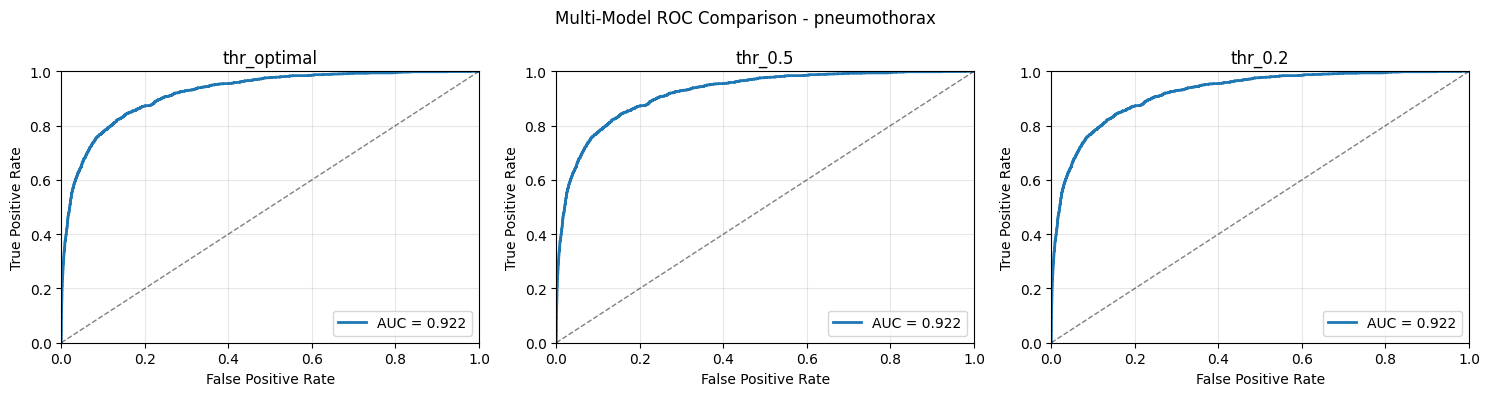

Saved plot: results/validation/multi_model_roc_support_devices.png


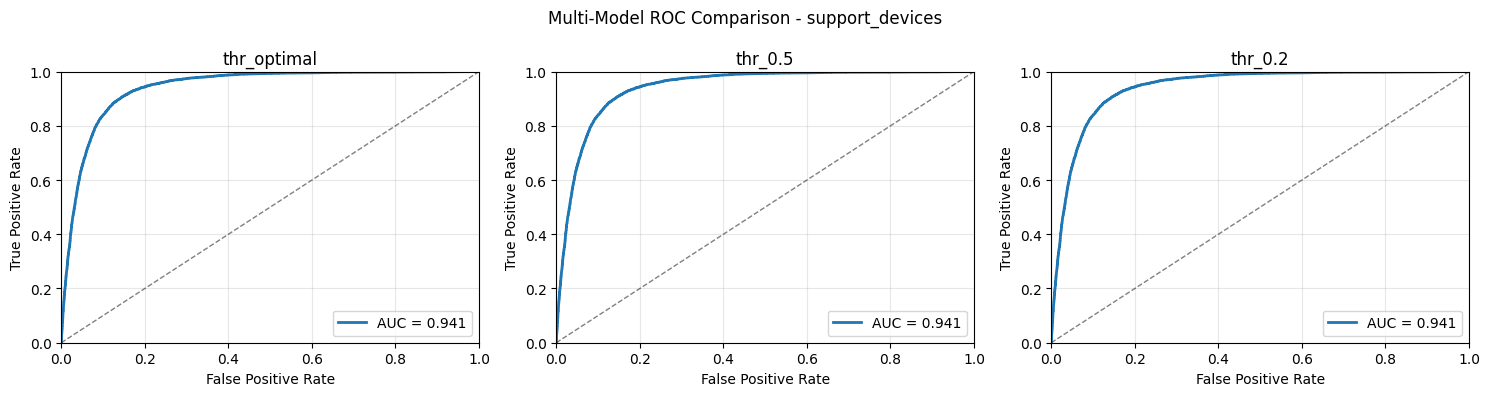

Saved plot: results/validation/multi_model_roc_no_finding.png


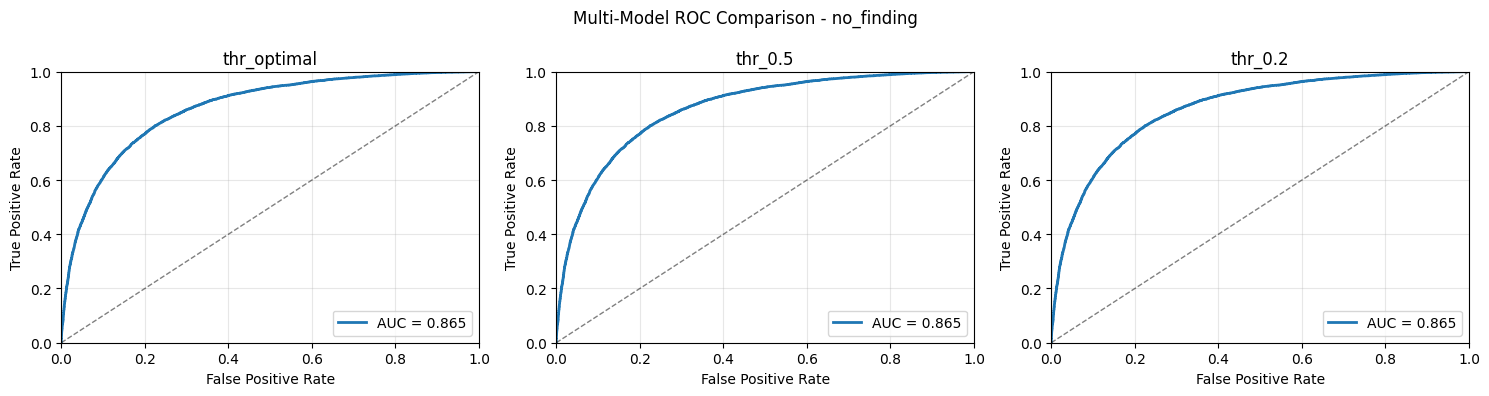

📈 Plotting Multi-Model PR Curves...
Saved plot: results/validation/multi_model_pr_pneumothorax.png


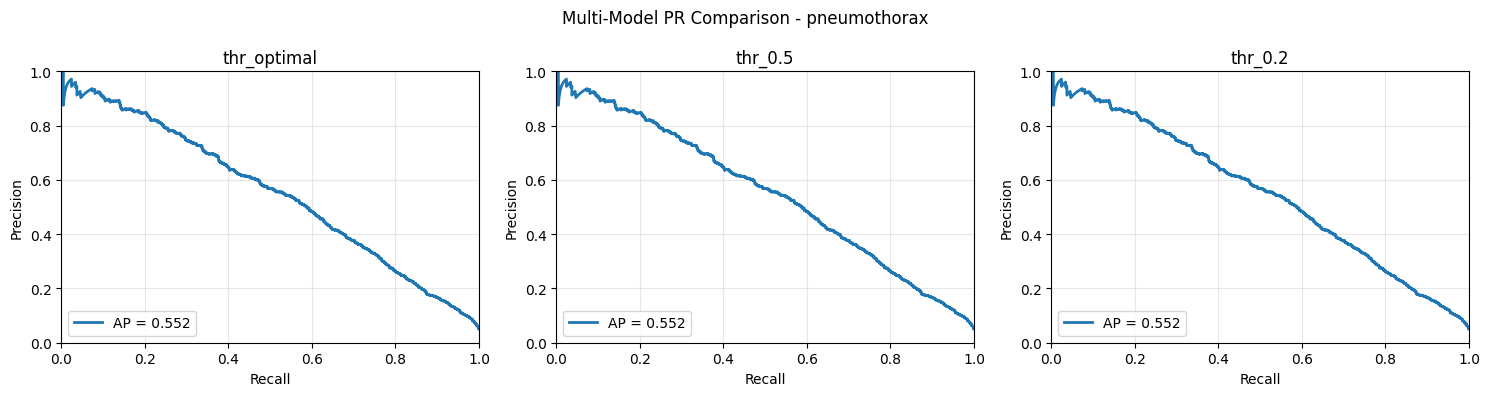

Saved plot: results/validation/multi_model_pr_support_devices.png


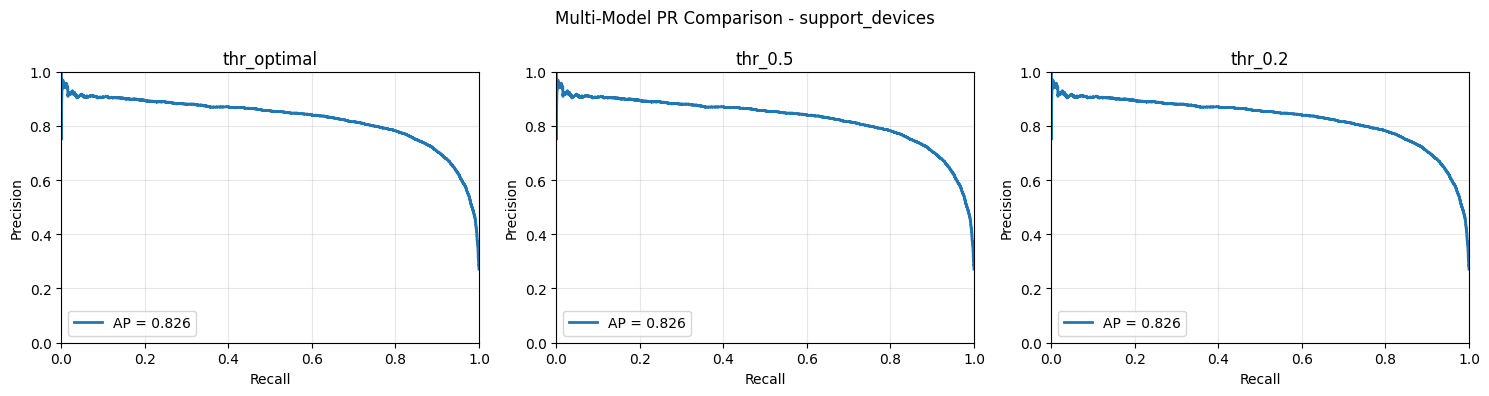

Saved plot: results/validation/multi_model_pr_no_finding.png


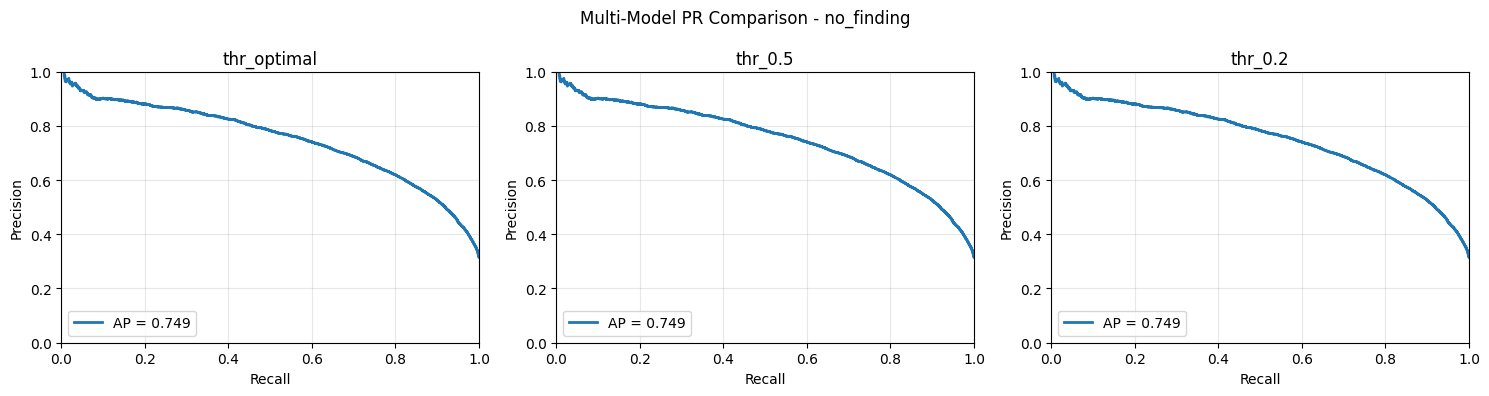

📈 Plotting Multi-Model ROC Curves with Datasets...
Saved plot: results/validation/multi_model_roc_with_datasets_pneumothorax.png


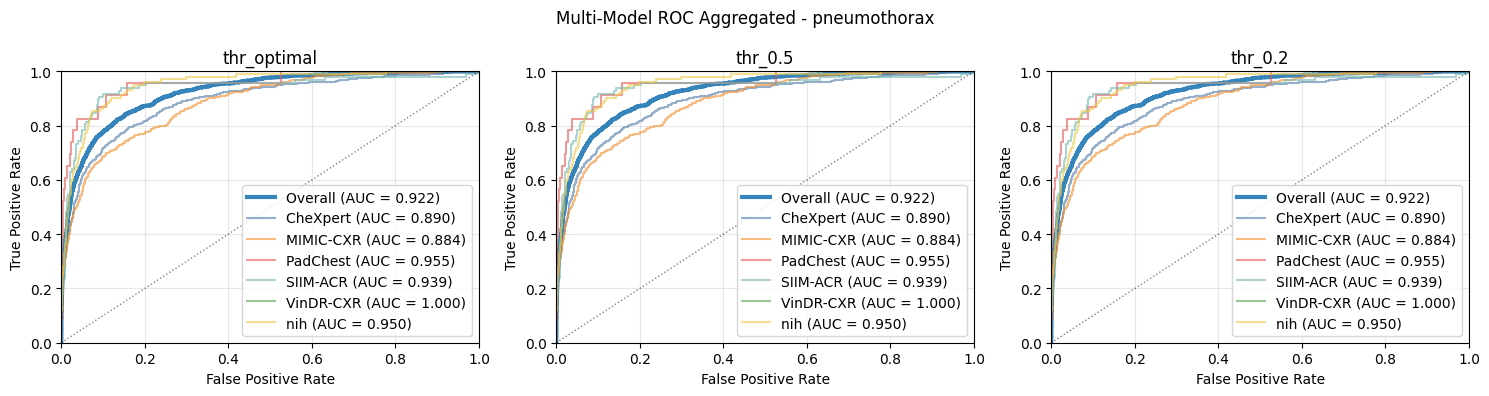

Saved plot: results/validation/multi_model_roc_with_datasets_support_devices.png


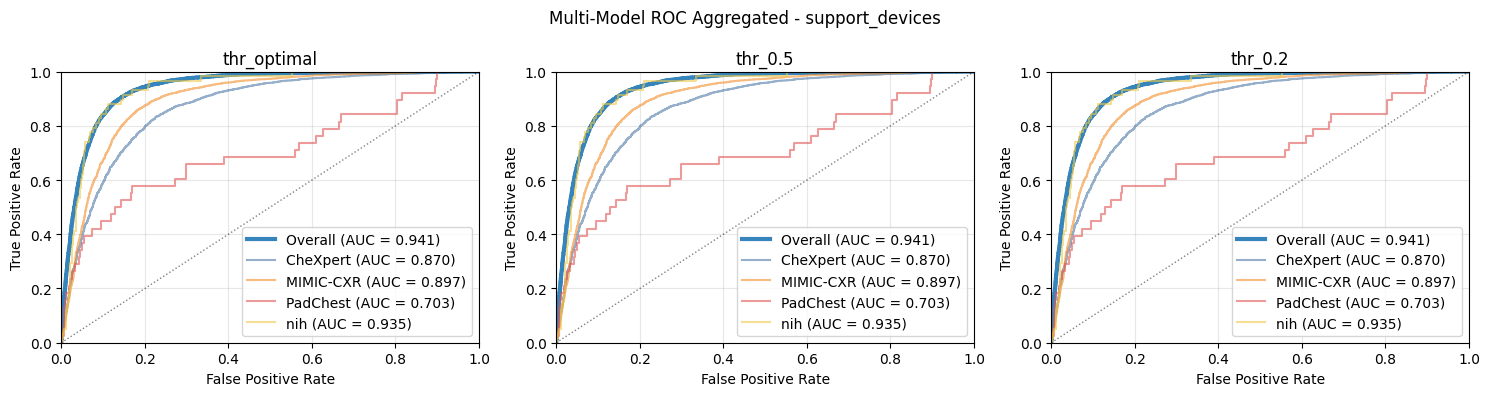

Saved plot: results/validation/multi_model_roc_with_datasets_no_finding.png


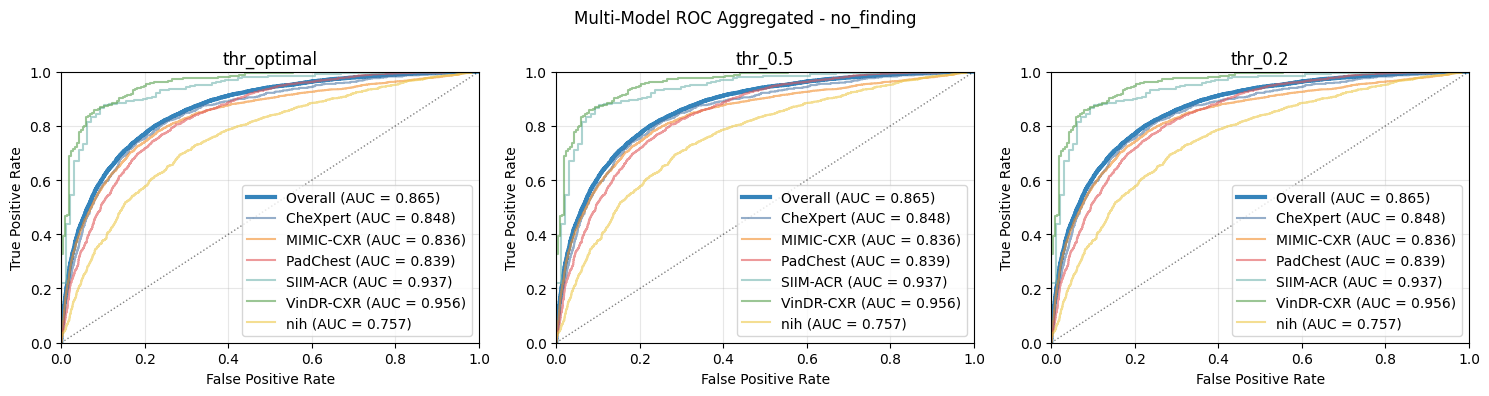

📈 Plotting Multi-Model PR Curves with Datasets...
Saved plot: results/validation/multi_model_pr_with_datasets_pneumothorax.png


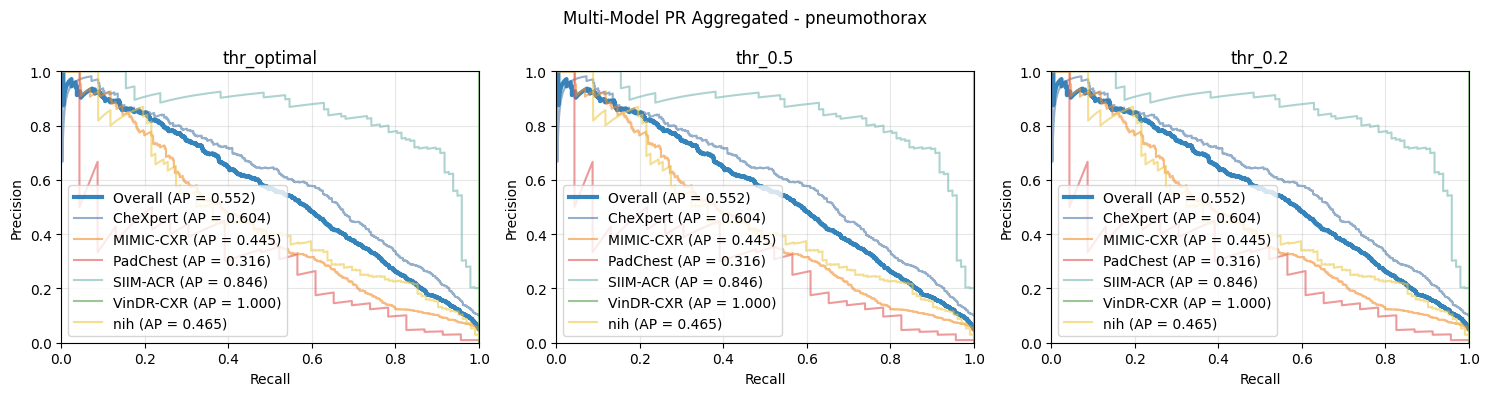

Saved plot: results/validation/multi_model_pr_with_datasets_support_devices.png


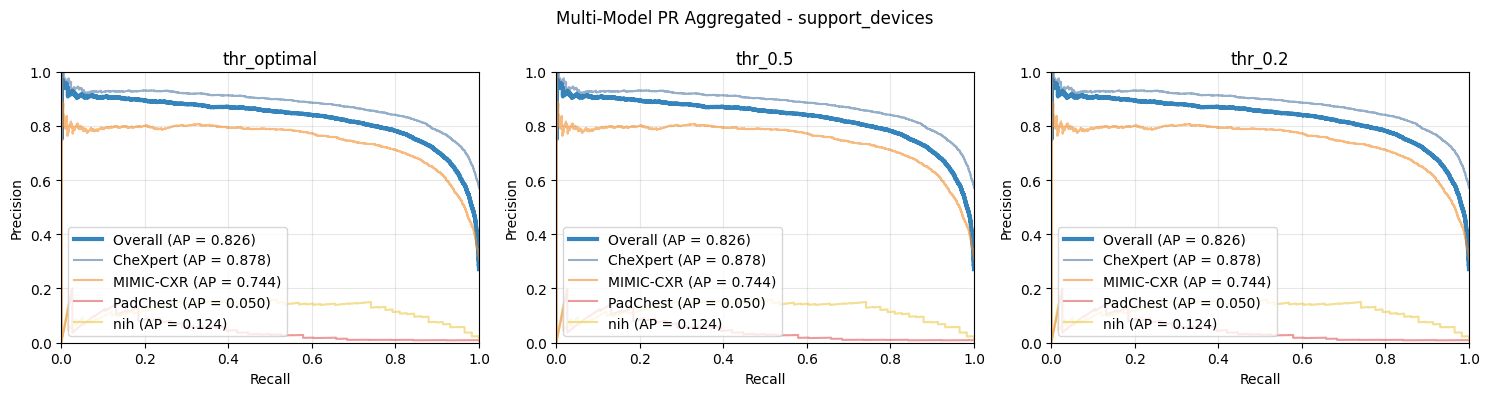

Saved plot: results/validation/multi_model_pr_with_datasets_no_finding.png


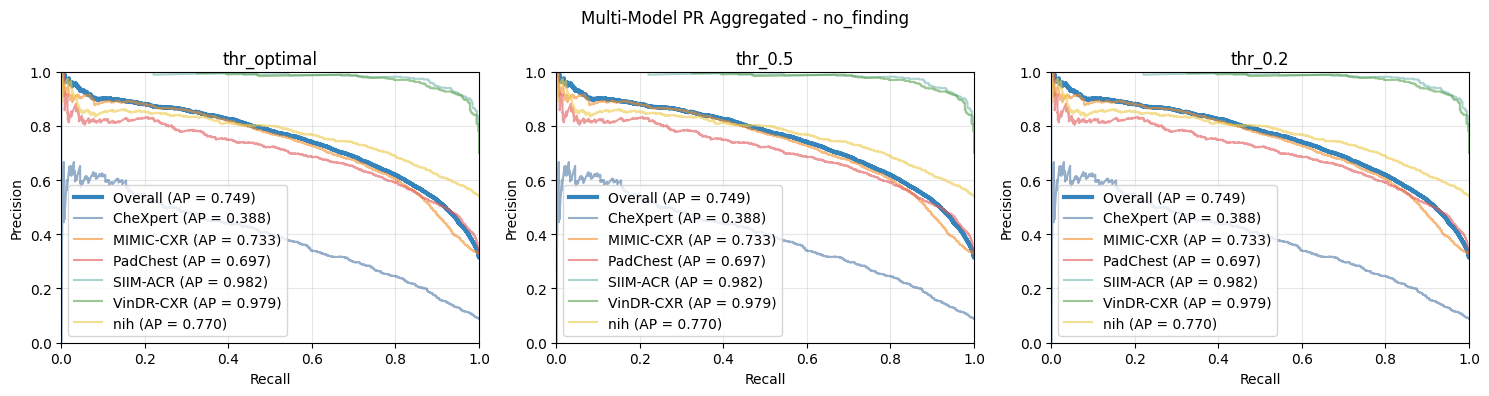

📊 Plotting Multi-Model Comparison - Sensitivity (Recall)...
Saved plot: results/validation/multi_model_comparison_Sensitivity_Recall_pneumothorax.png


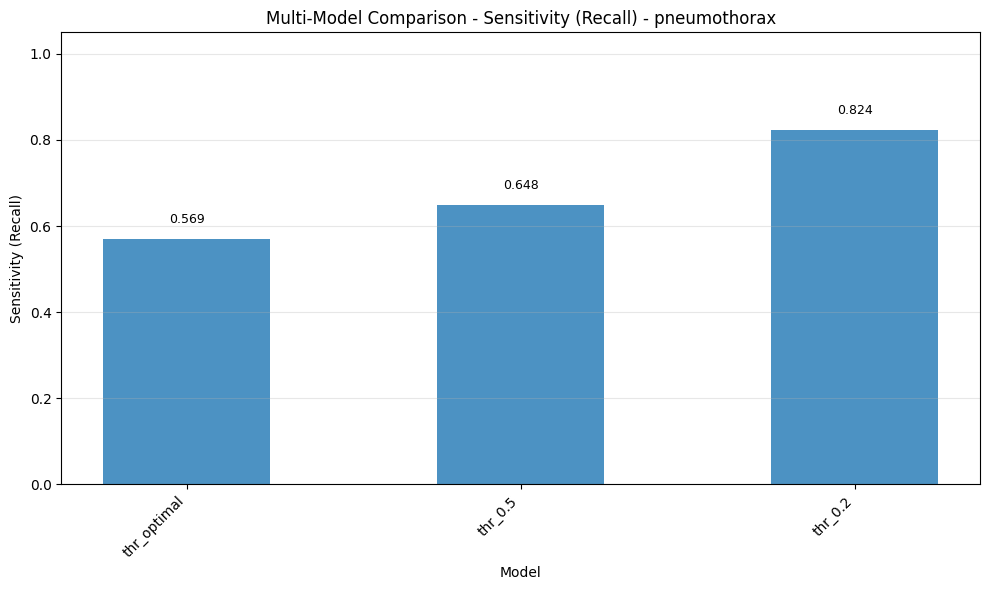

Saved plot: results/validation/multi_model_comparison_Sensitivity_Recall_support_devices.png


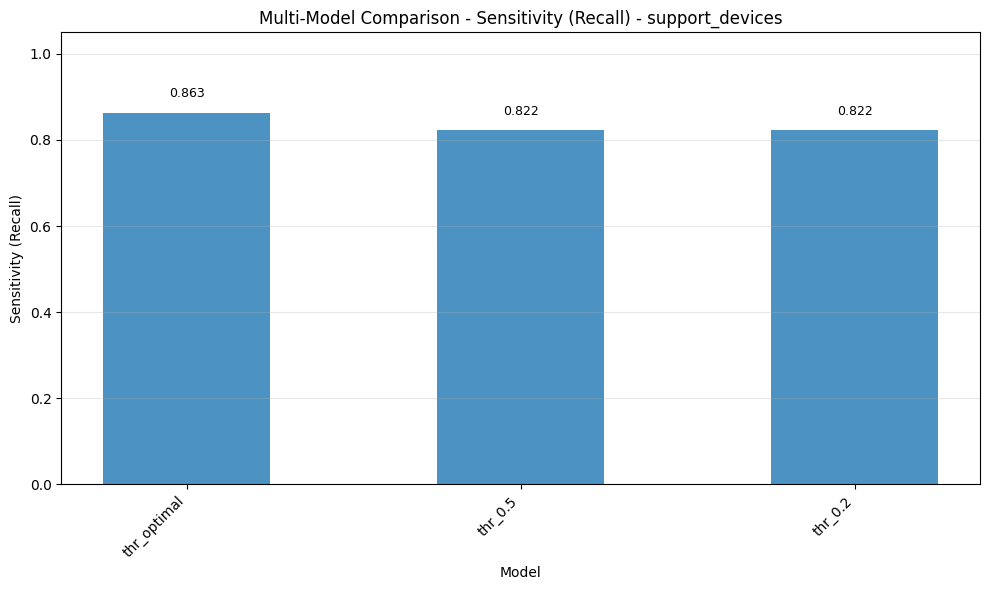

Saved plot: results/validation/multi_model_comparison_Sensitivity_Recall_no_finding.png


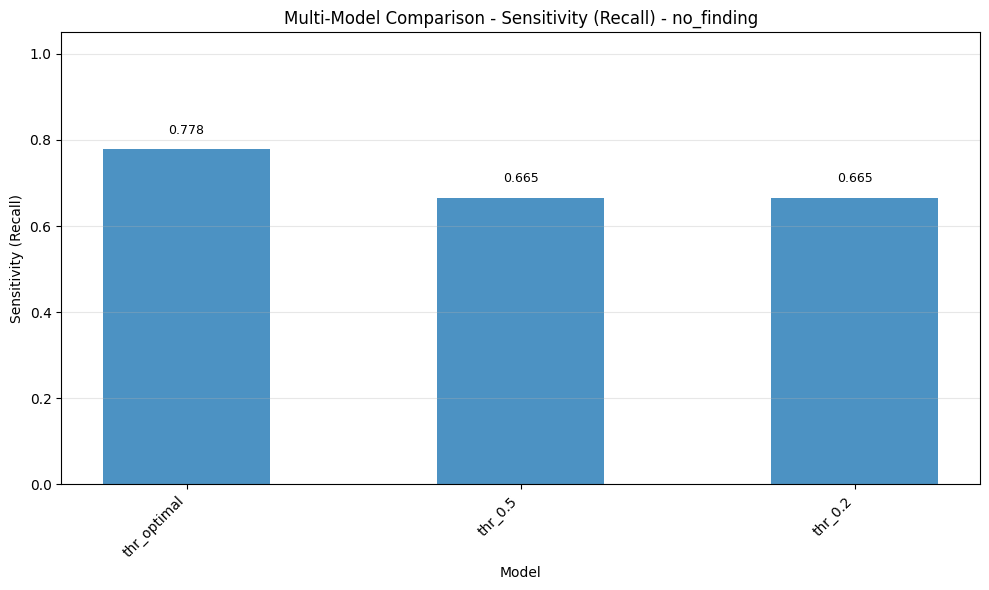

📊 Plotting Multi-Model Comparison - Specificity...
Saved plot: results/validation/multi_model_comparison_Specificity_pneumothorax.png


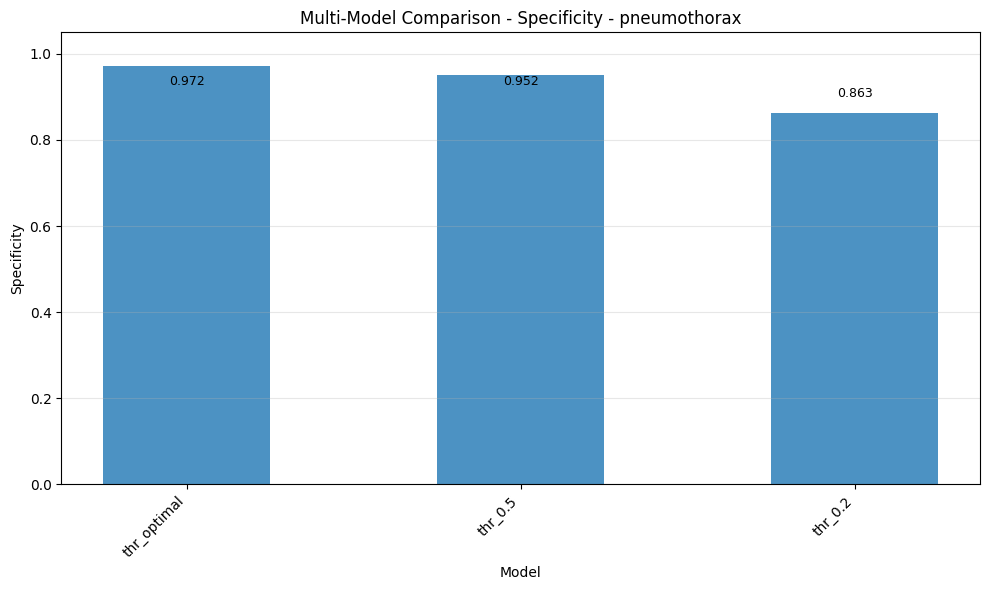

Saved plot: results/validation/multi_model_comparison_Specificity_support_devices.png


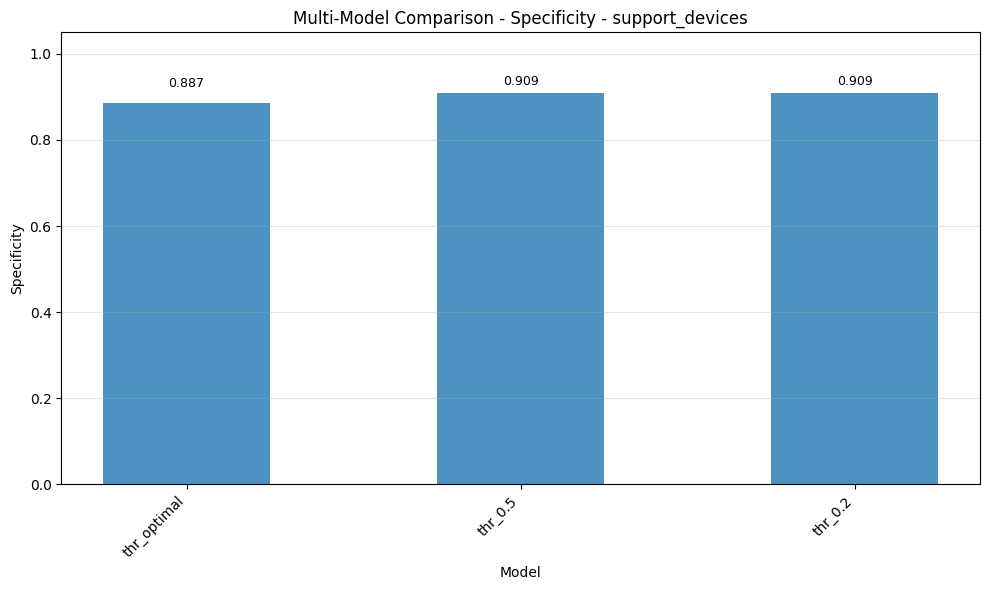

Saved plot: results/validation/multi_model_comparison_Specificity_no_finding.png


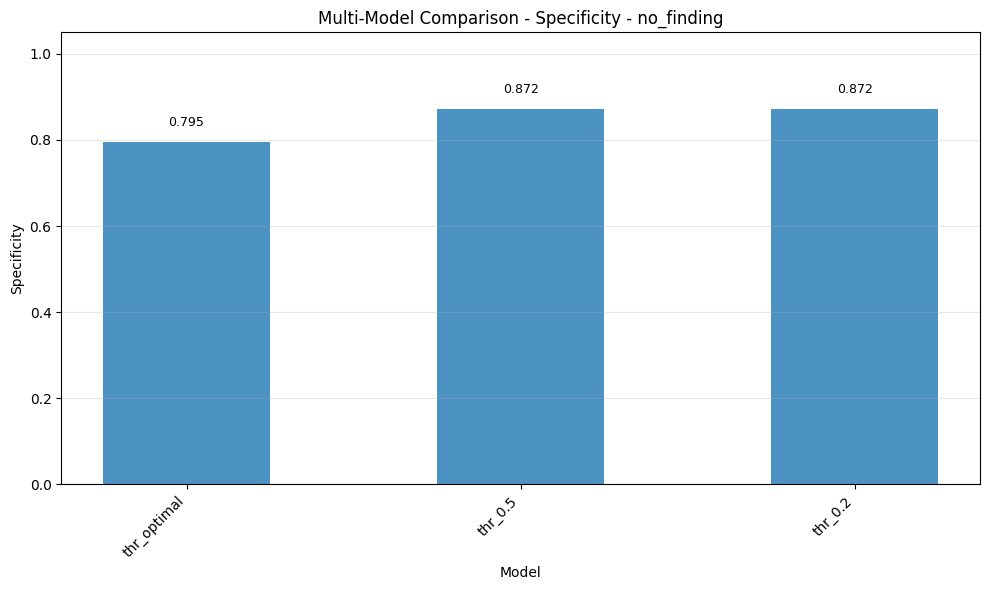

📊 Plotting Multi-Model Comparison - PPV (Precision)...
Saved plot: results/validation/multi_model_comparison_PPV_Precision_pneumothorax.png


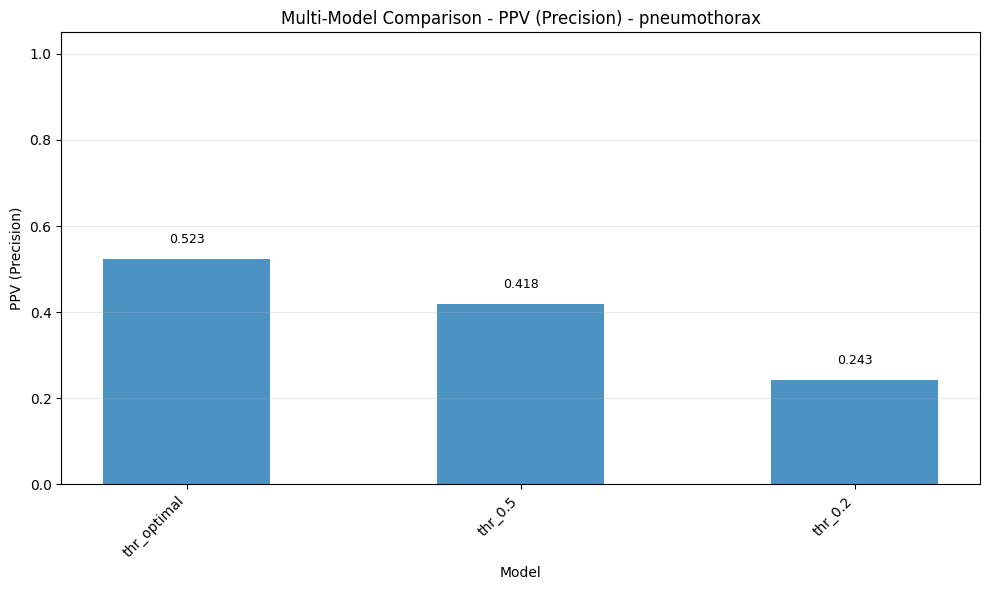

Saved plot: results/validation/multi_model_comparison_PPV_Precision_support_devices.png


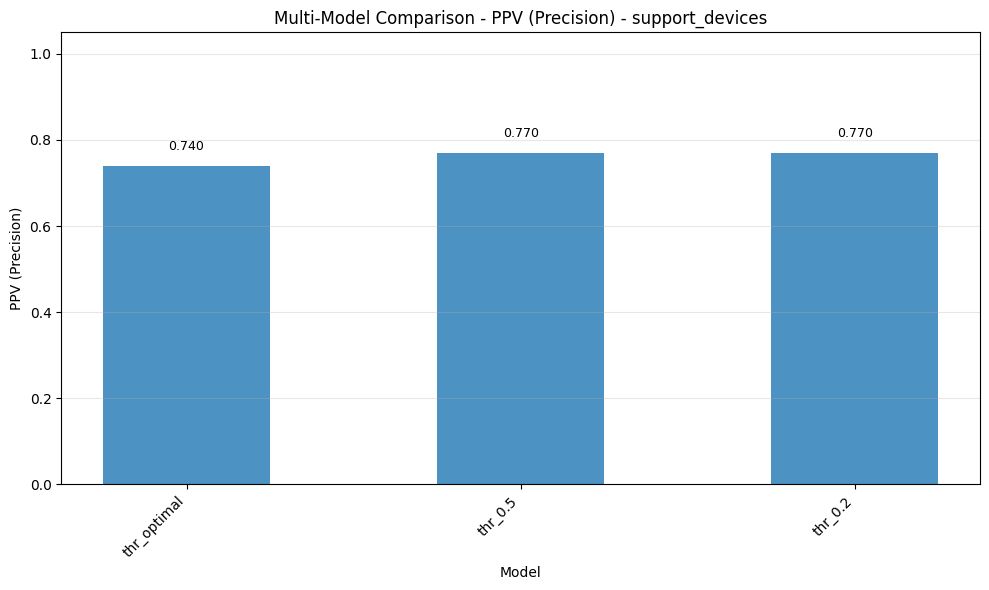

Saved plot: results/validation/multi_model_comparison_PPV_Precision_no_finding.png


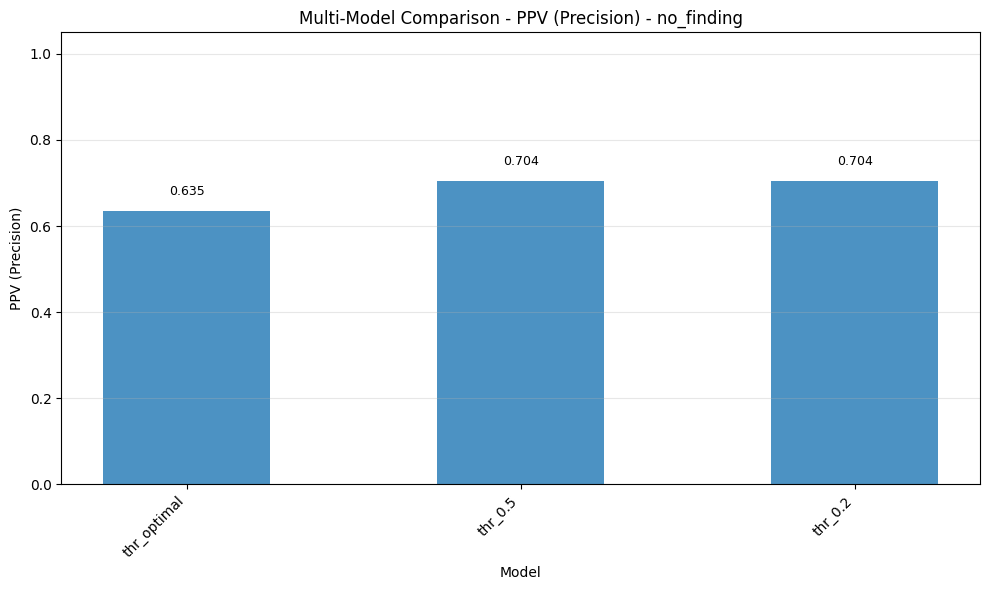

📊 Plotting Multi-Model Comparison - NPV...
Saved plot: results/validation/multi_model_comparison_NPV_pneumothorax.png


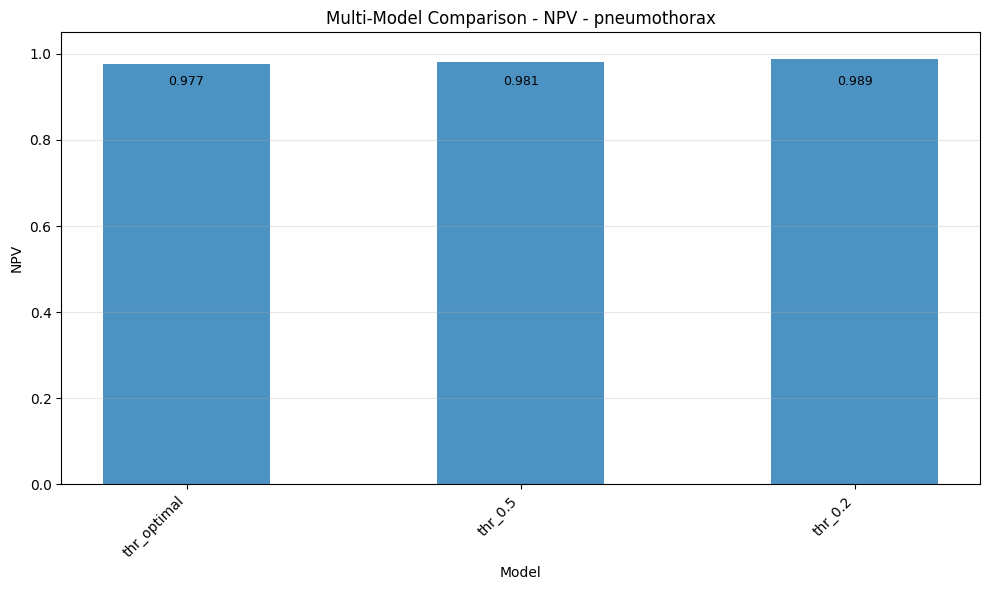

Saved plot: results/validation/multi_model_comparison_NPV_support_devices.png


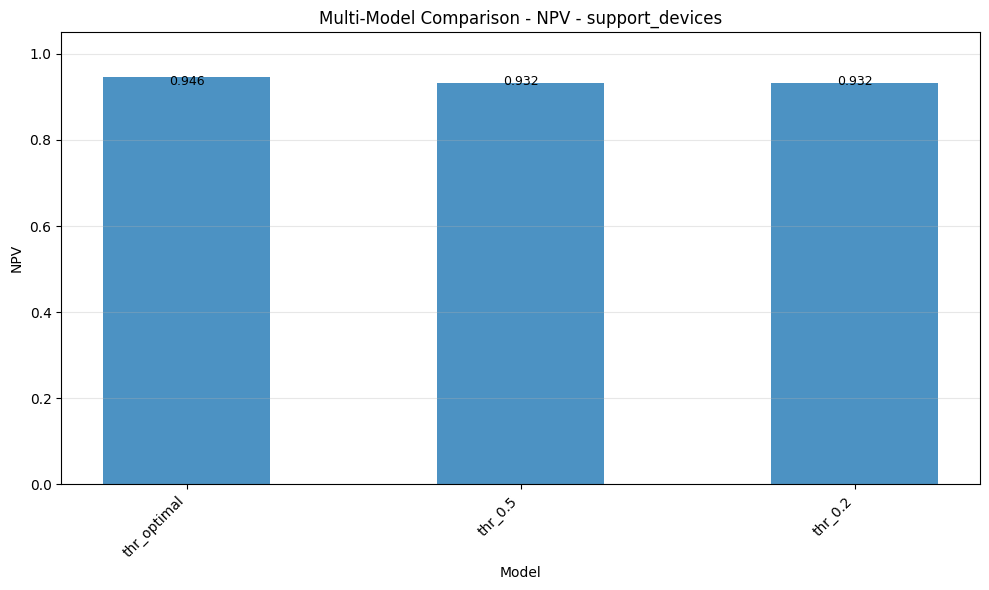

Saved plot: results/validation/multi_model_comparison_NPV_no_finding.png


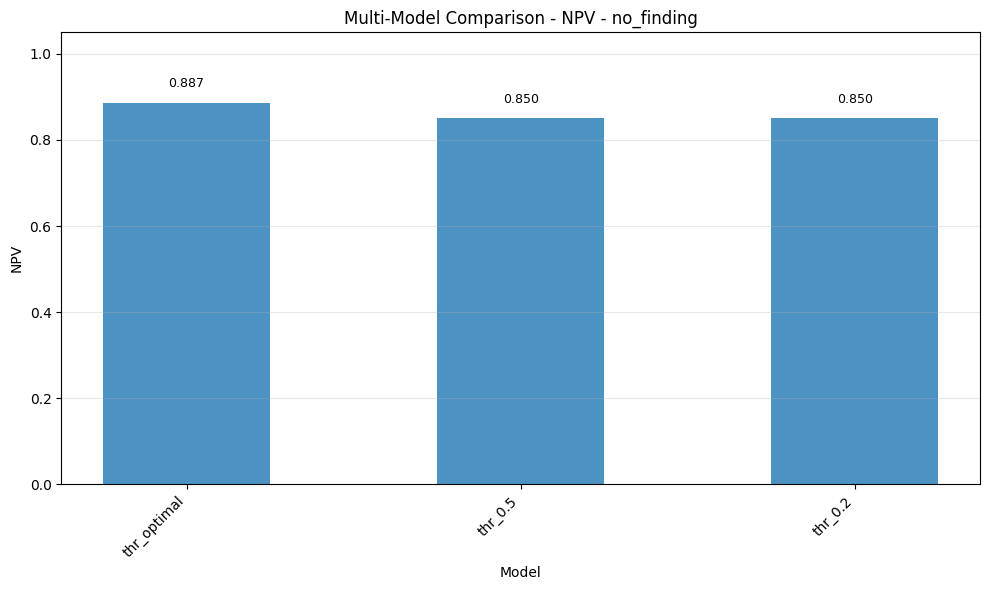

📊 Plotting Multi-Model Comparison - F1-score...
Saved plot: results/validation/multi_model_comparison_F1-score_pneumothorax.png


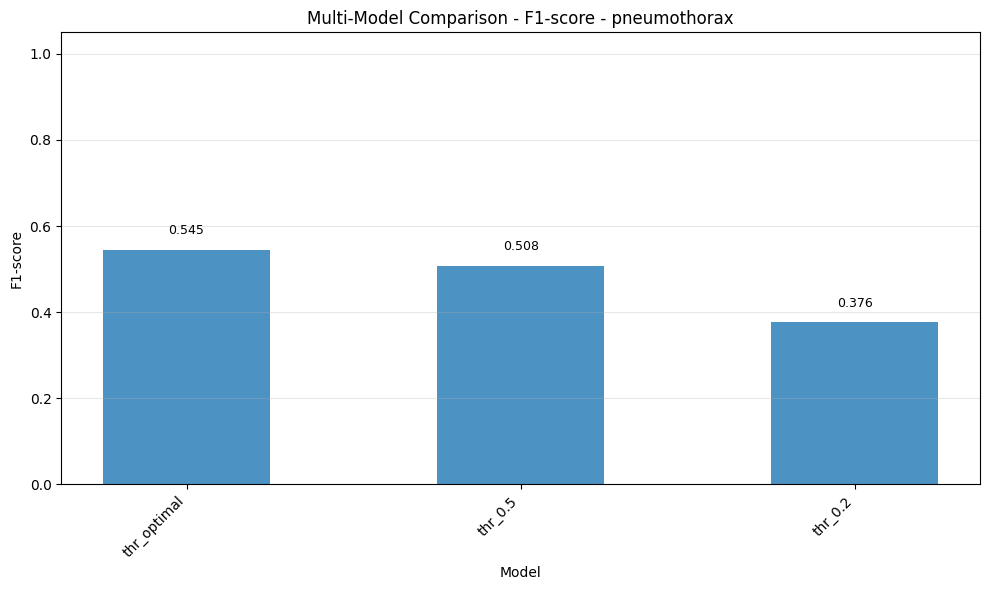

Saved plot: results/validation/multi_model_comparison_F1-score_support_devices.png


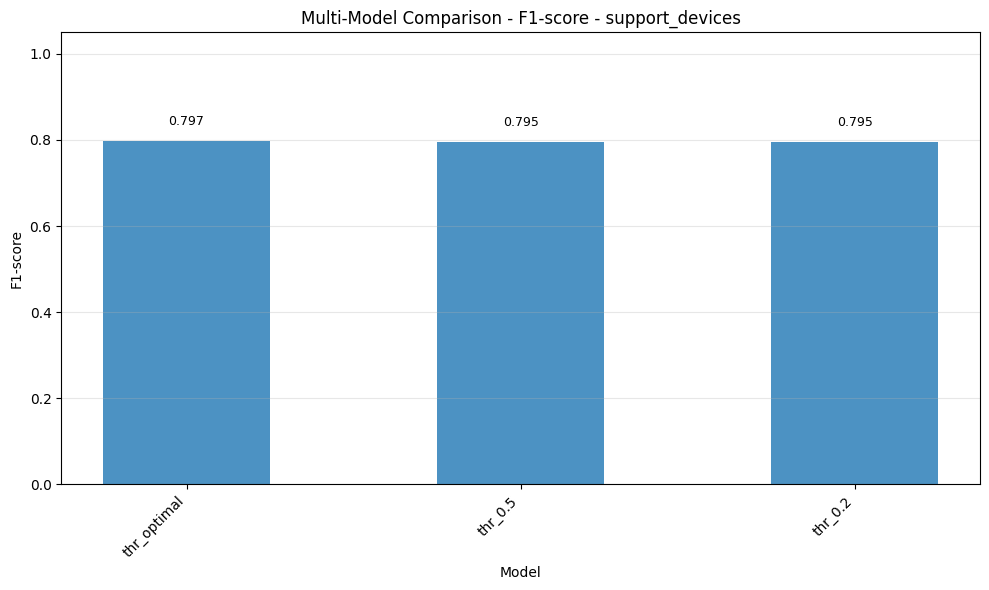

Saved plot: results/validation/multi_model_comparison_F1-score_no_finding.png


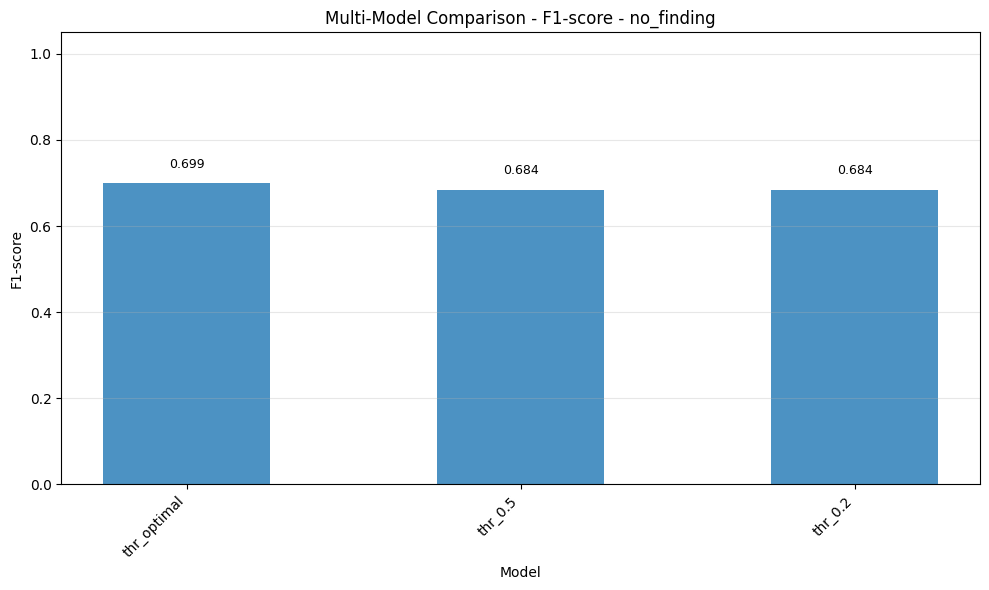

📊 Plotting Multi-Model Comparison - AUC...
Saved plot: results/validation/multi_model_comparison_AUC_pneumothorax.png


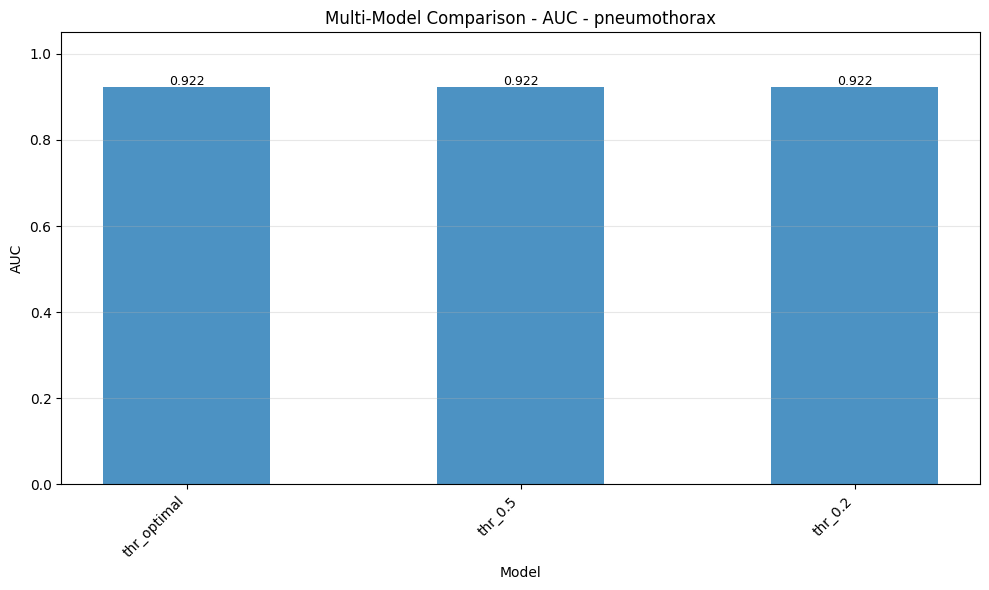

Saved plot: results/validation/multi_model_comparison_AUC_support_devices.png


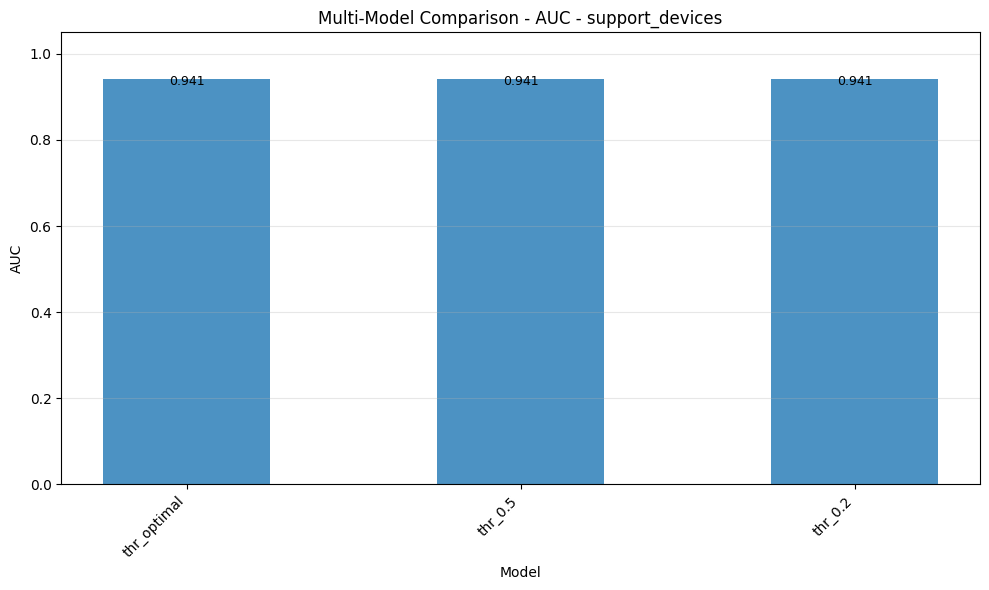

Saved plot: results/validation/multi_model_comparison_AUC_no_finding.png


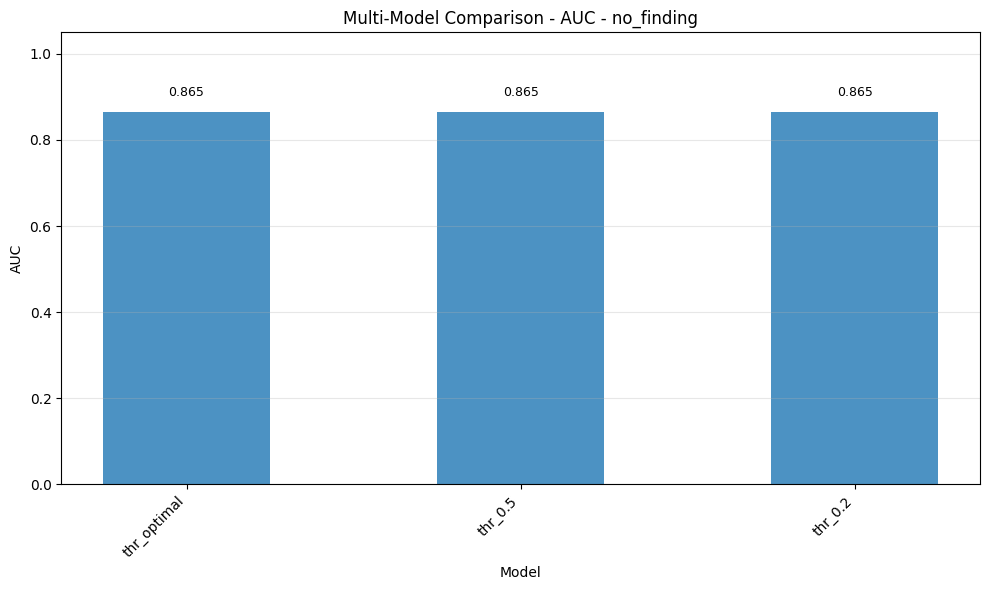

📊 Plotting Multi-Model Comparison - AP...
Saved plot: results/validation/multi_model_comparison_AP_pneumothorax.png


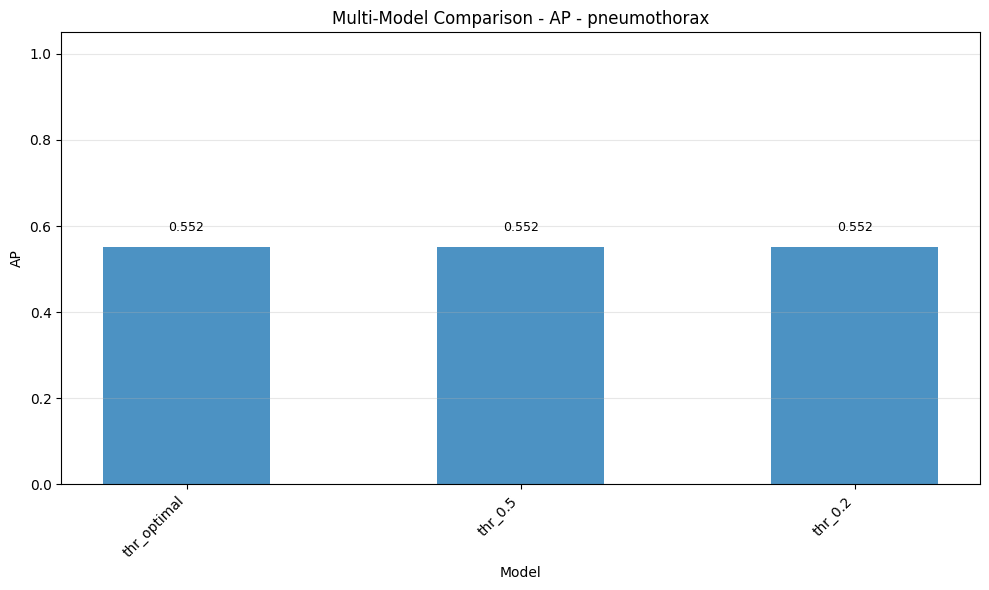

Saved plot: results/validation/multi_model_comparison_AP_support_devices.png


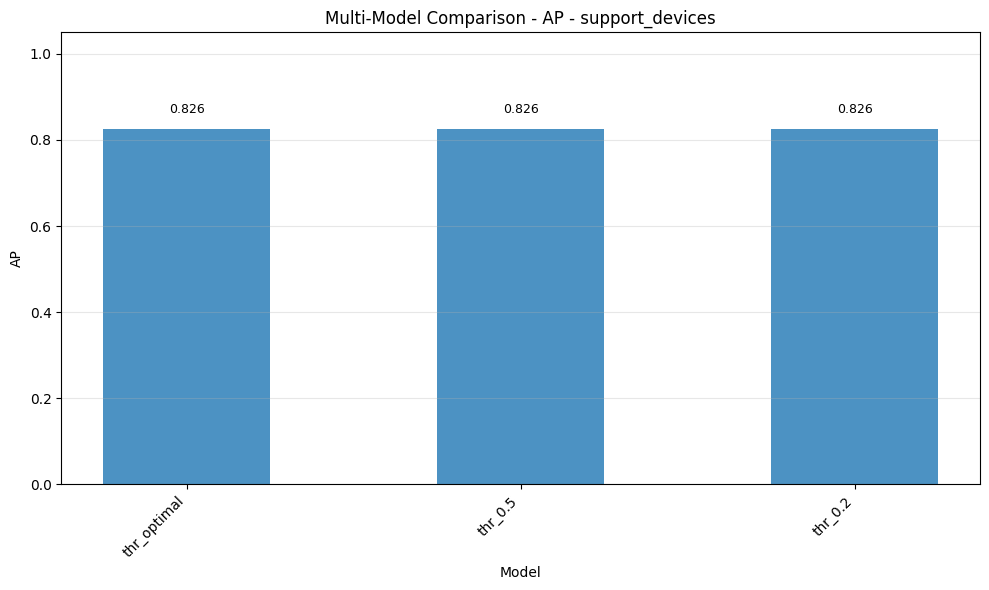

Saved plot: results/validation/multi_model_comparison_AP_no_finding.png


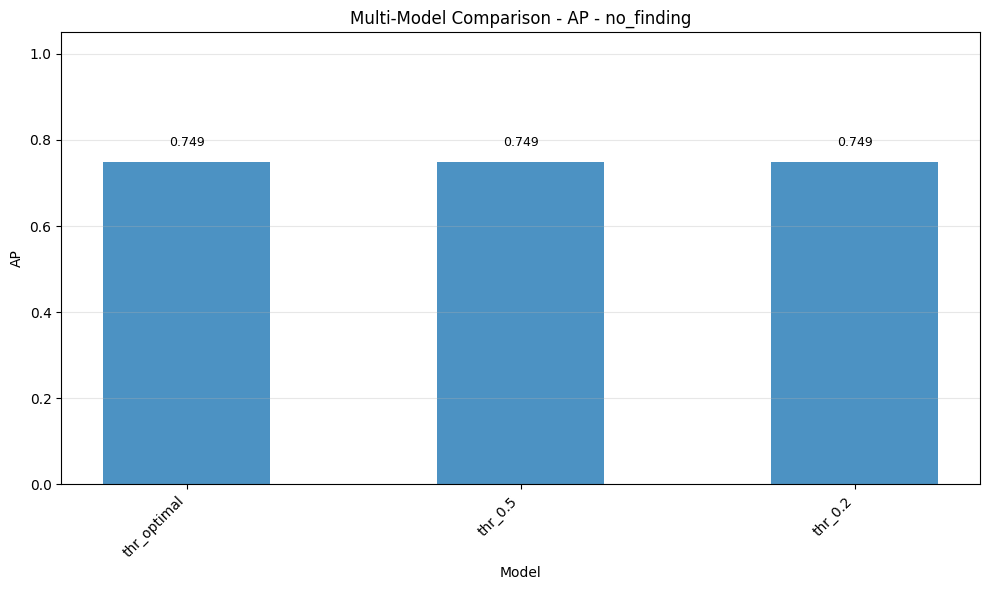

📊 Plotting Multi-Model Comprehensive Comparison...
Saved plot: results/validation/multi_model_comprehensive_pneumothorax.png


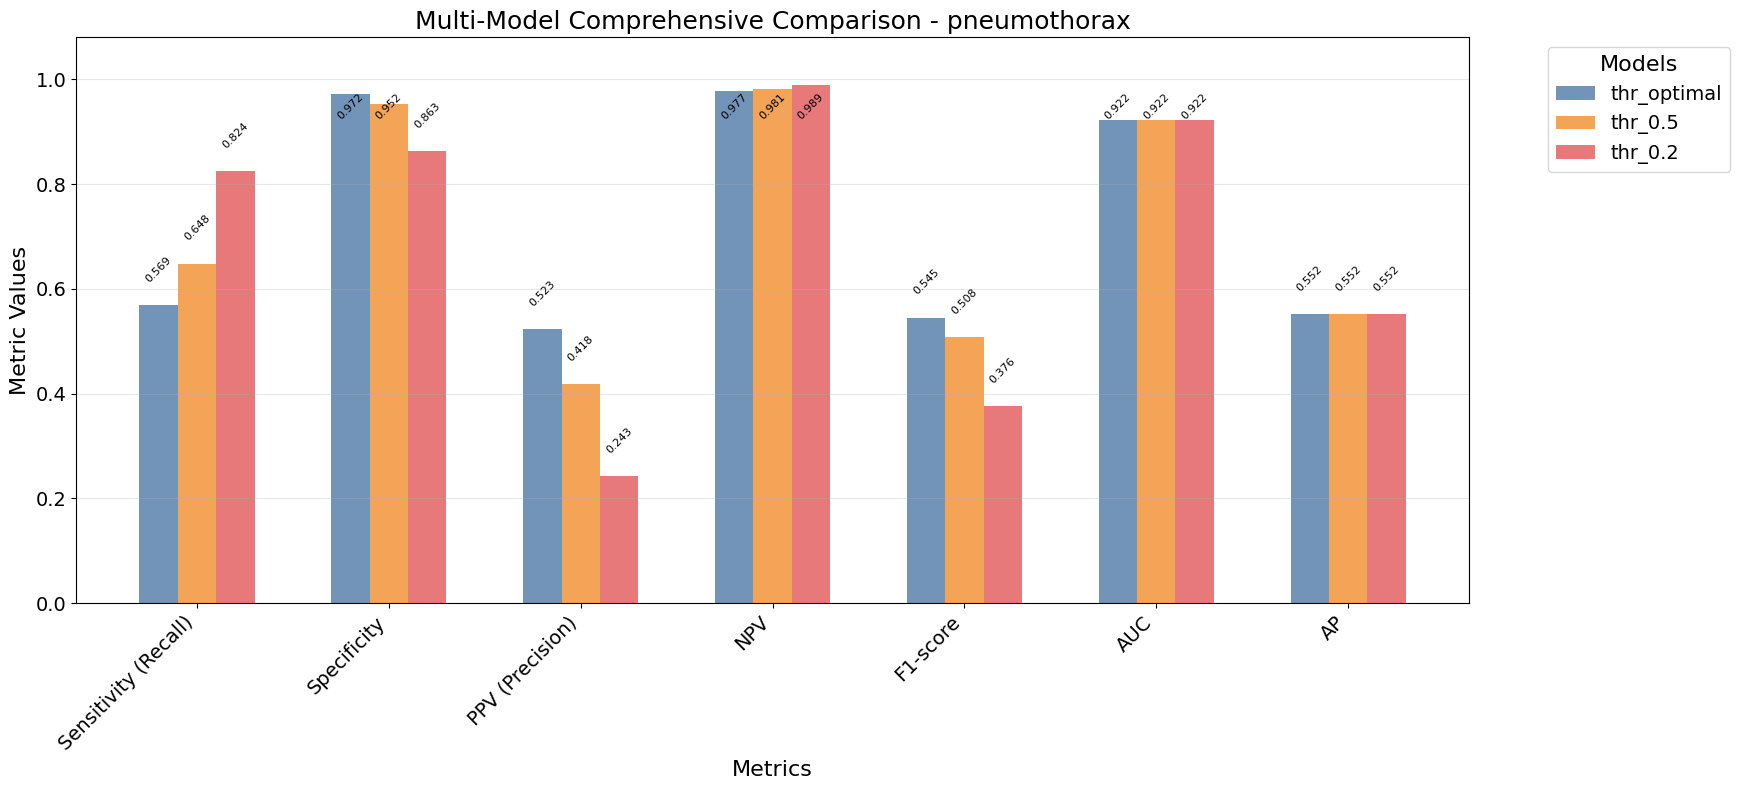

Saved plot: results/validation/multi_model_comprehensive_support_devices.png


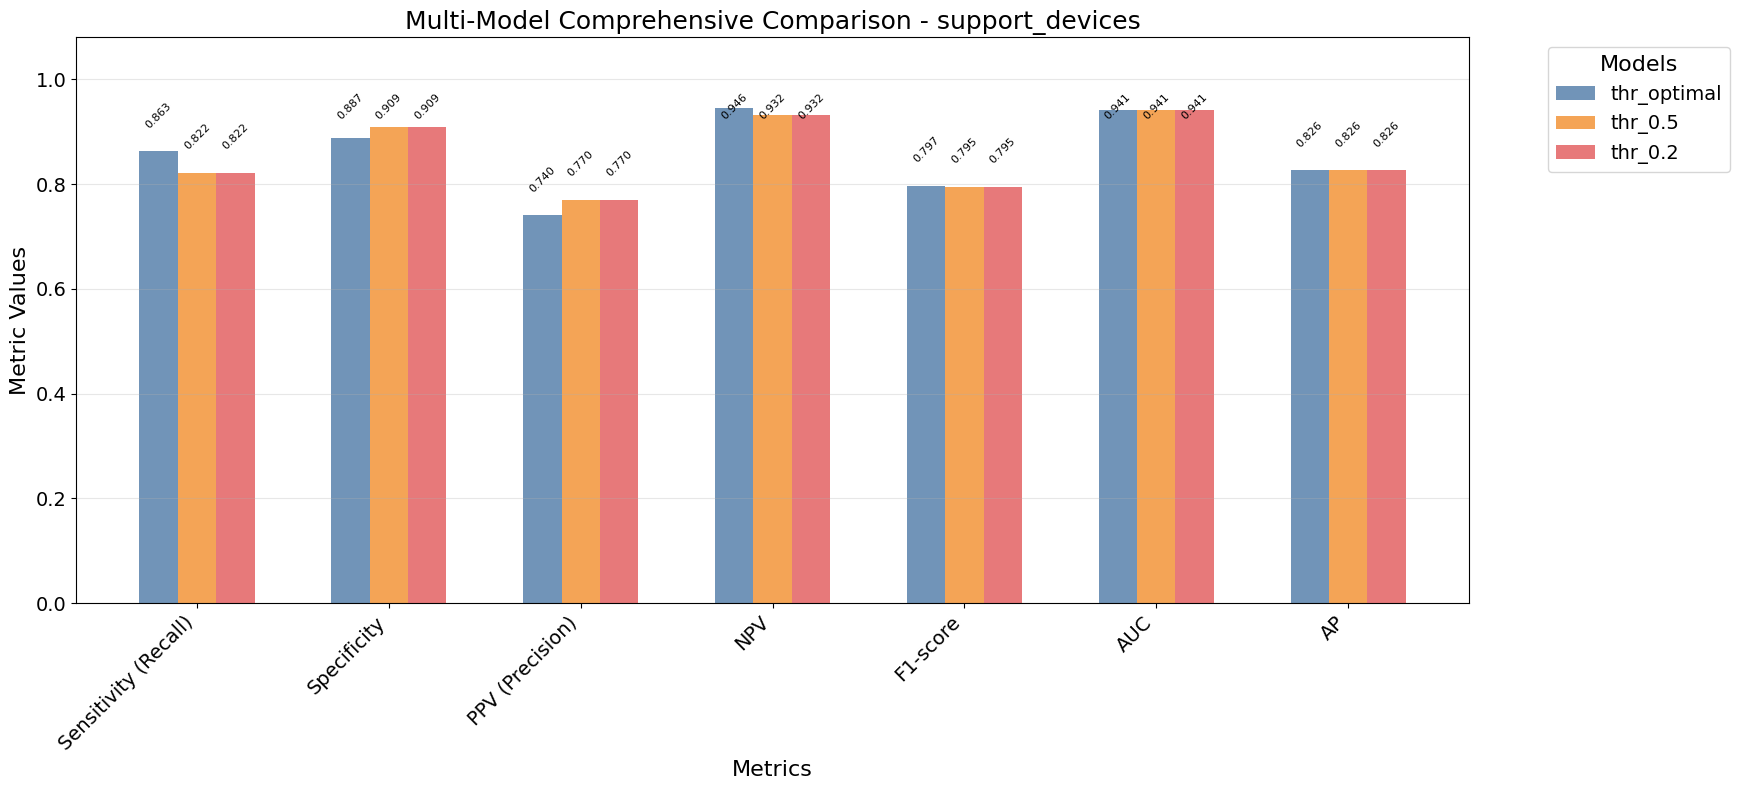

Saved plot: results/validation/multi_model_comprehensive_no_finding.png


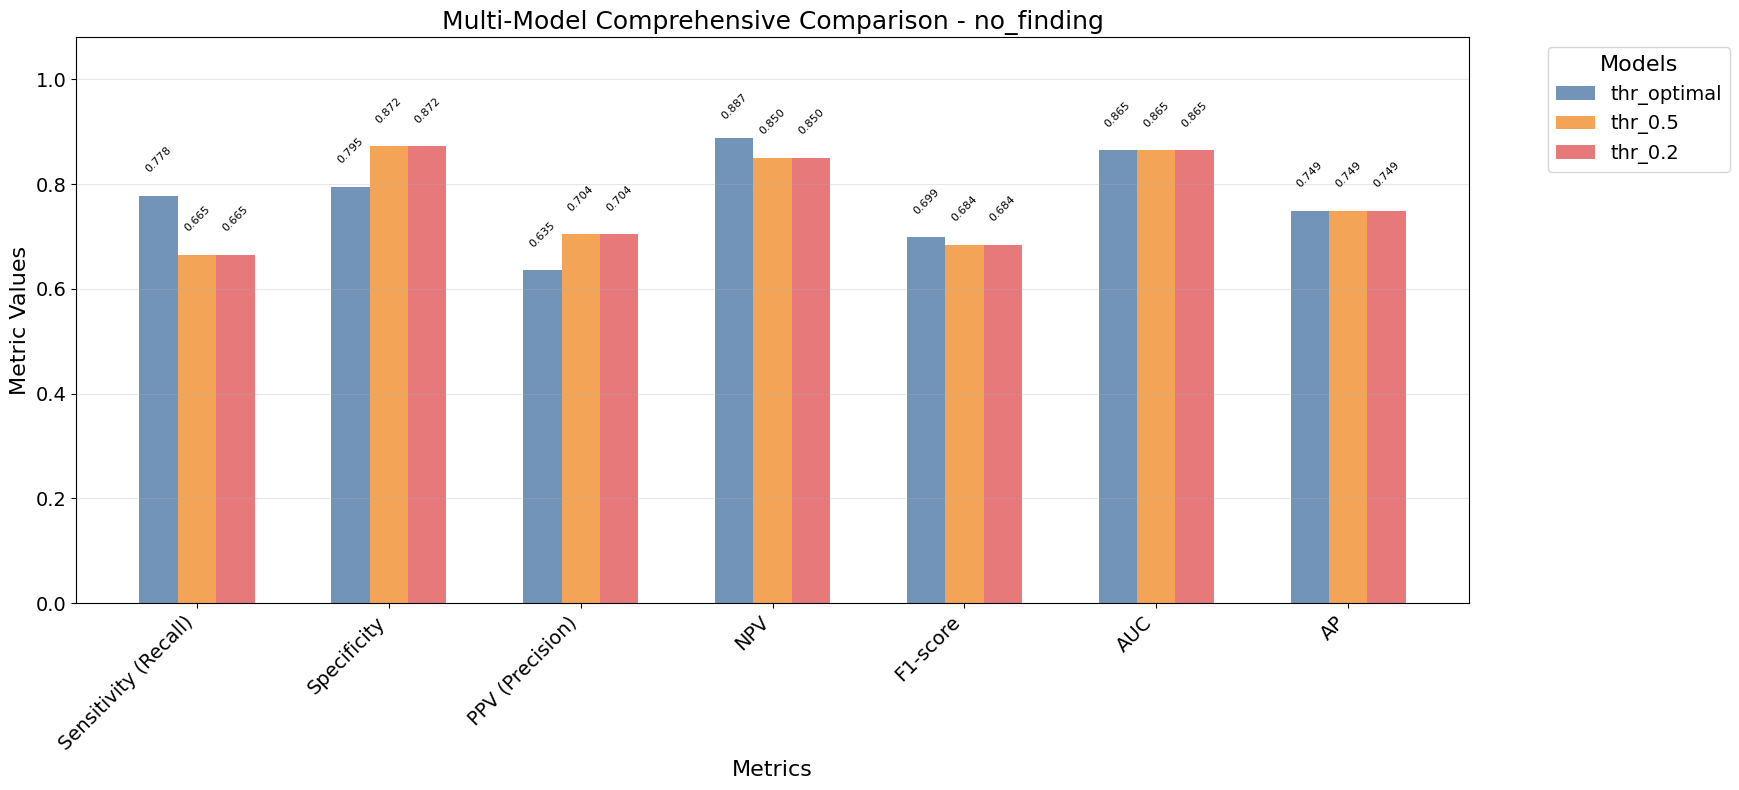

📊 Plotting Multi-Model Confusion Matrices...
Saved plot: results/validation/multi_model_confusion_matrices_pneumothorax.png


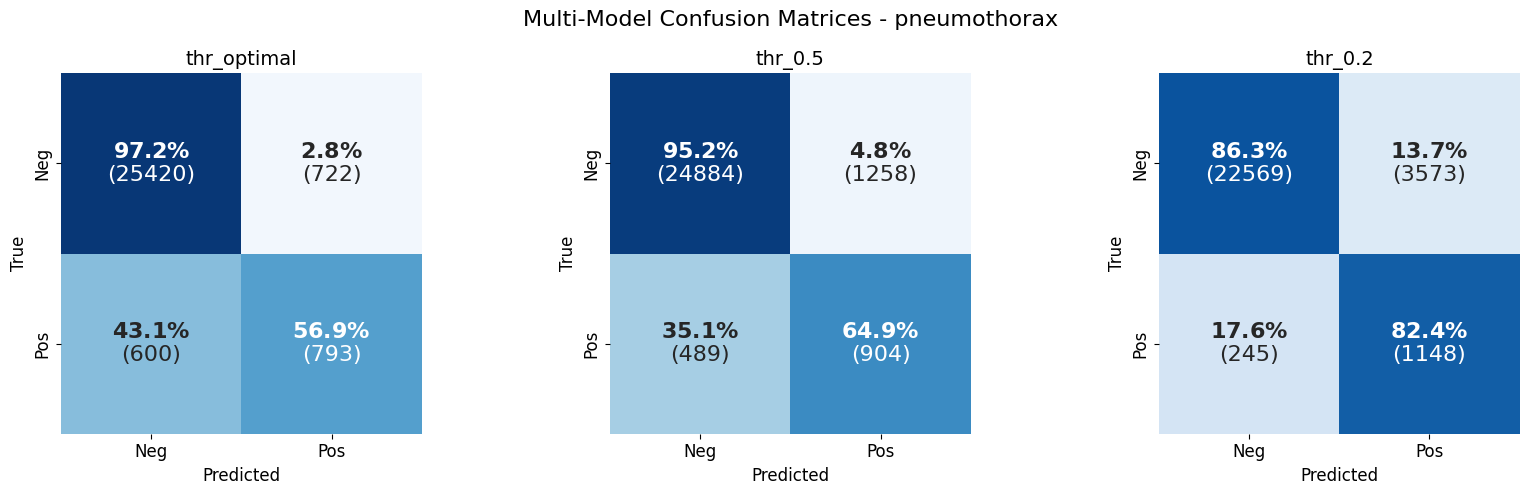

Saved plot: results/validation/multi_model_confusion_matrices_support_devices.png


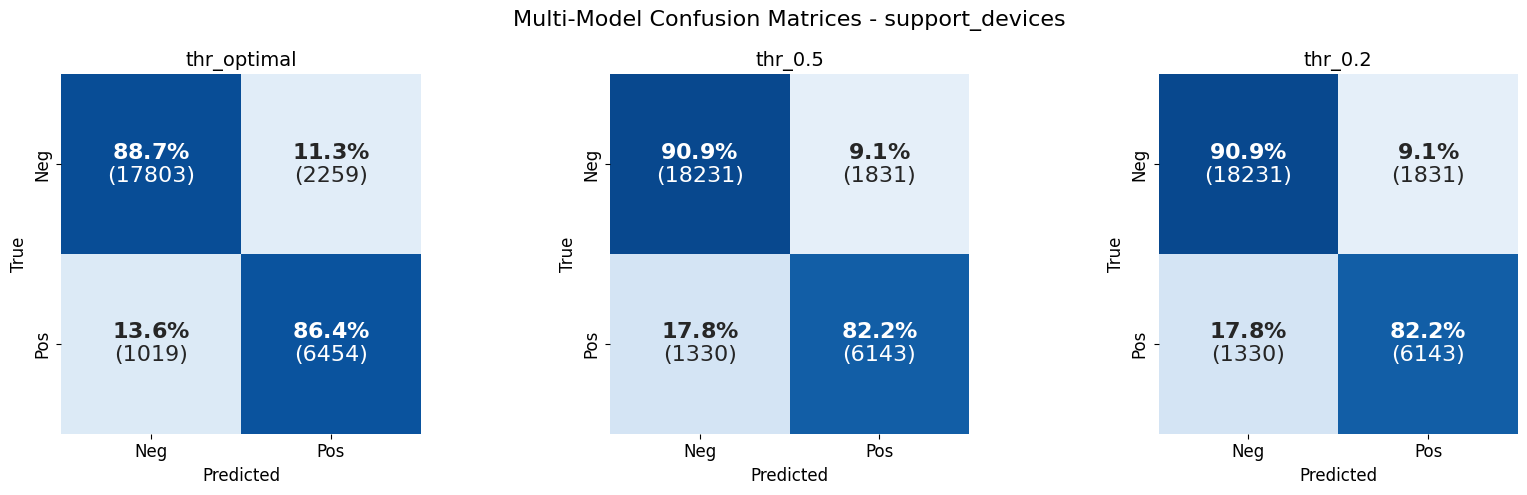

Saved plot: results/validation/multi_model_confusion_matrices_no_finding.png


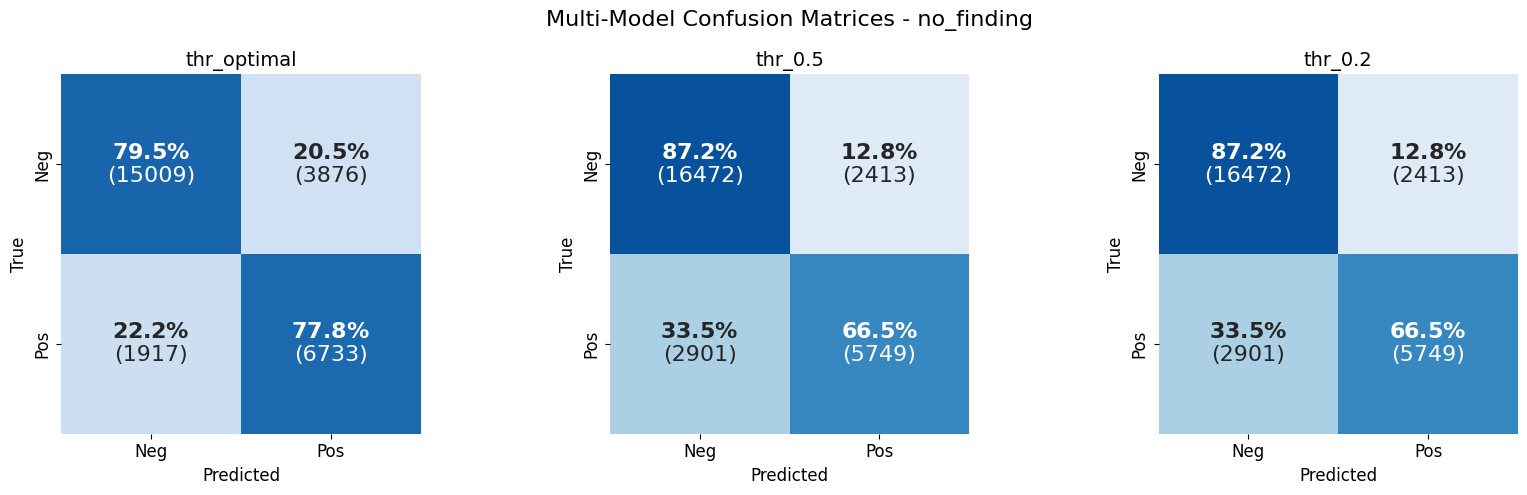

📊 Plotting Multi-Model Dataset Confusion Matrices...


cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/validation/multi_model_dataset_confusion_matrices_pneumothorax.png


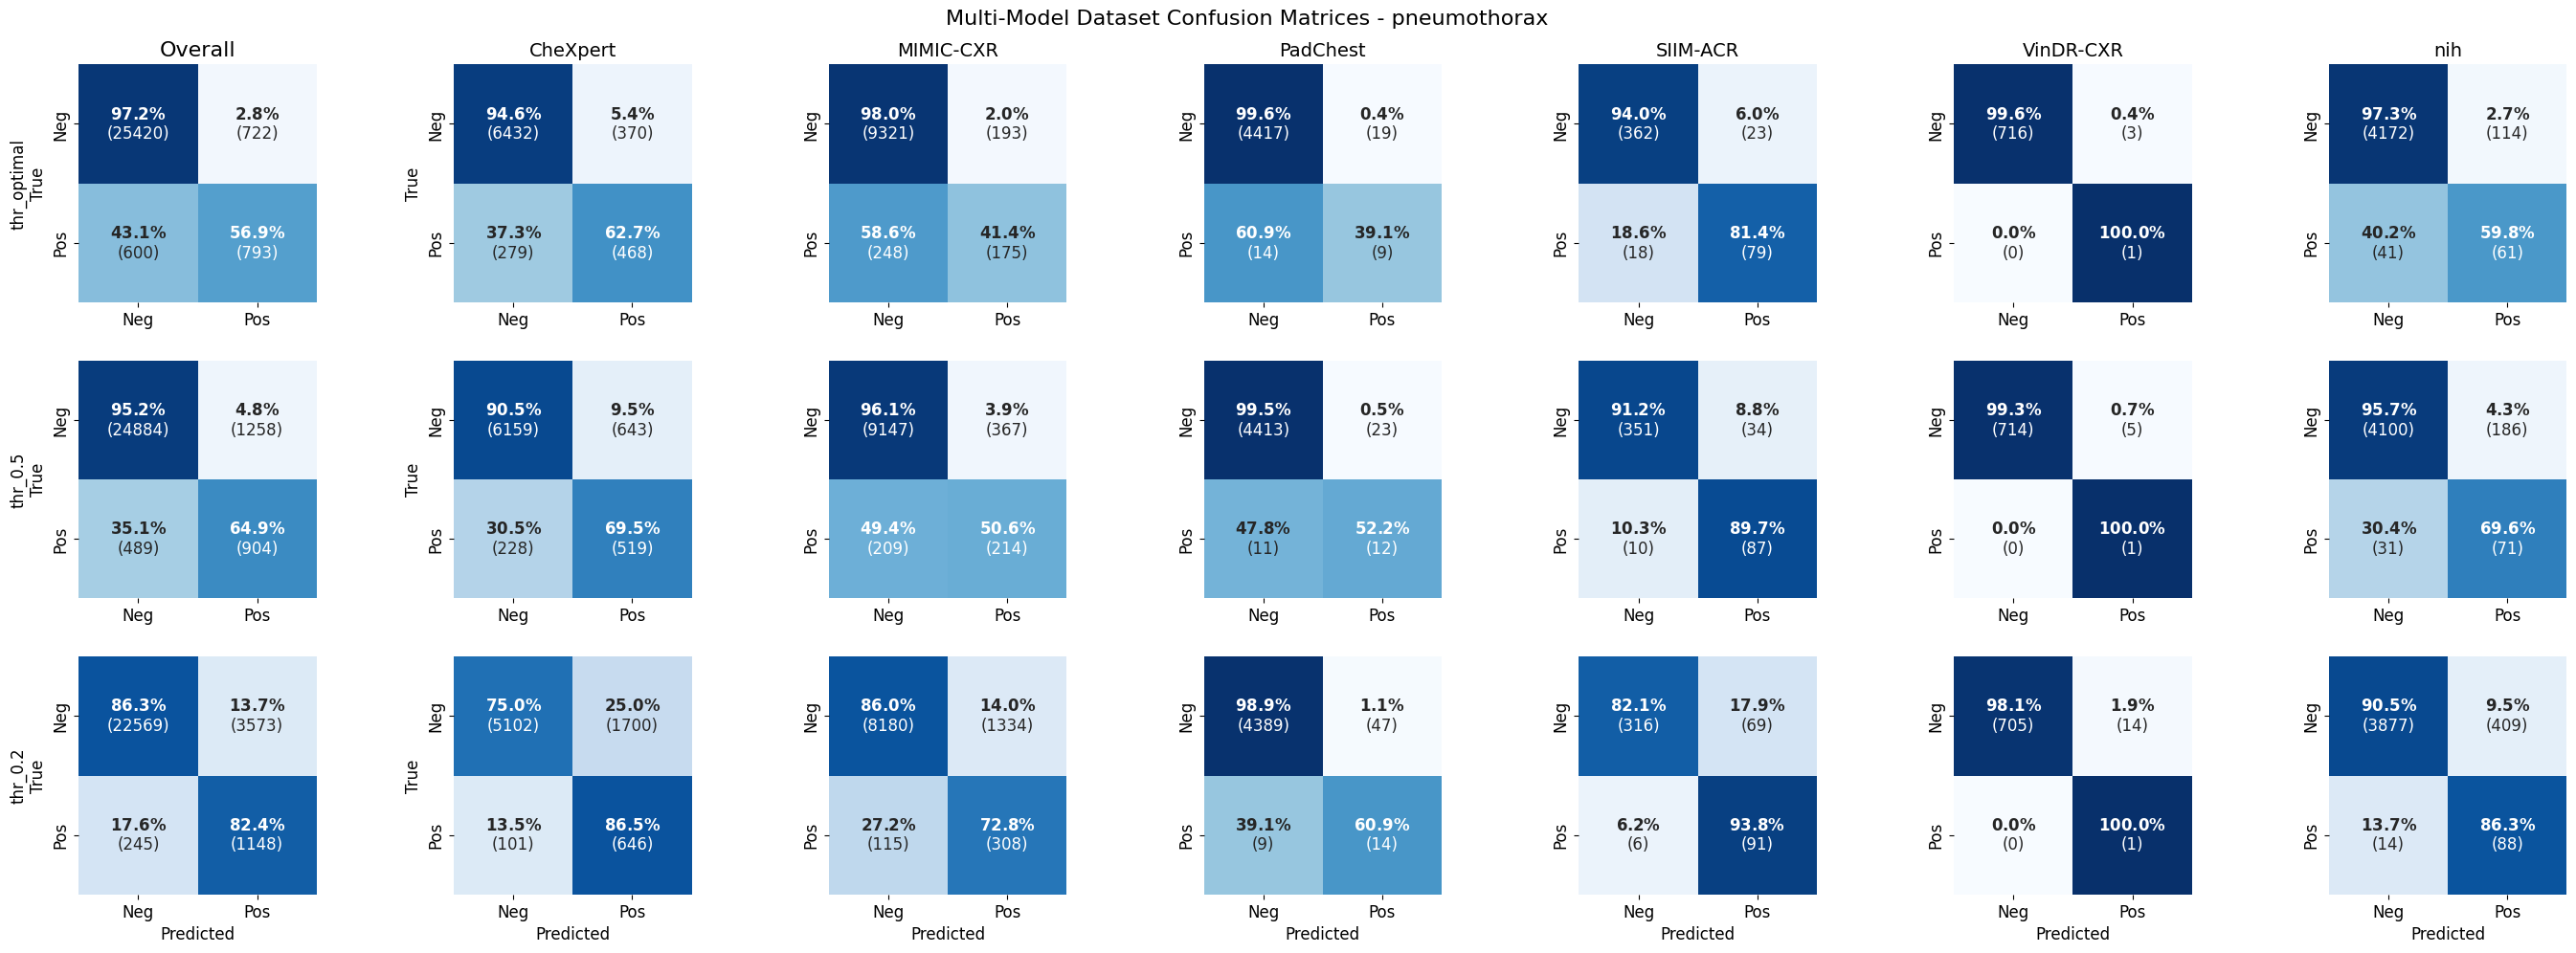

cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/validation/multi_model_dataset_confusion_matrices_support_devices.png


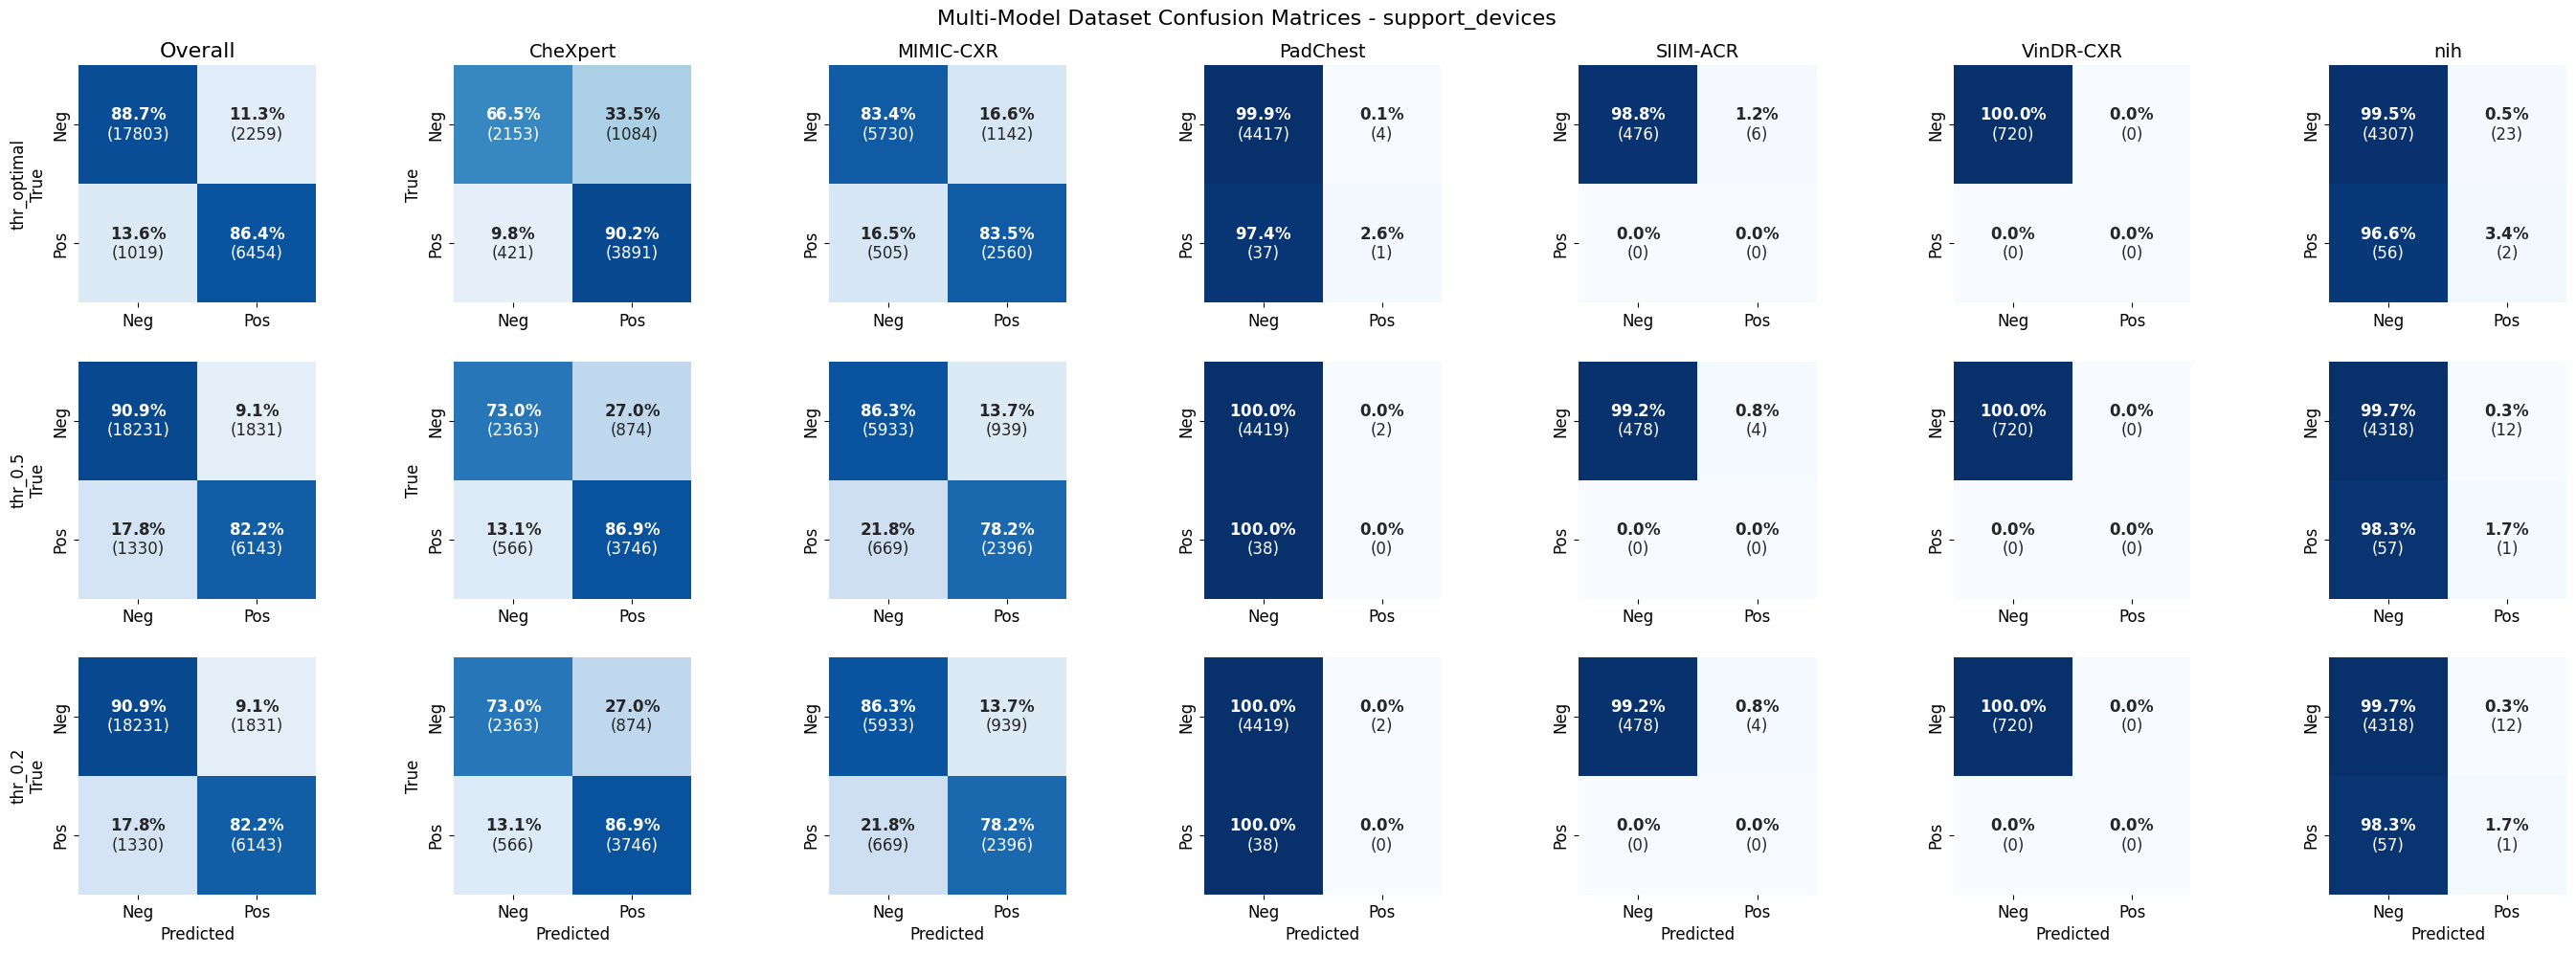

cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/validation/multi_model_dataset_confusion_matrices_no_finding.png


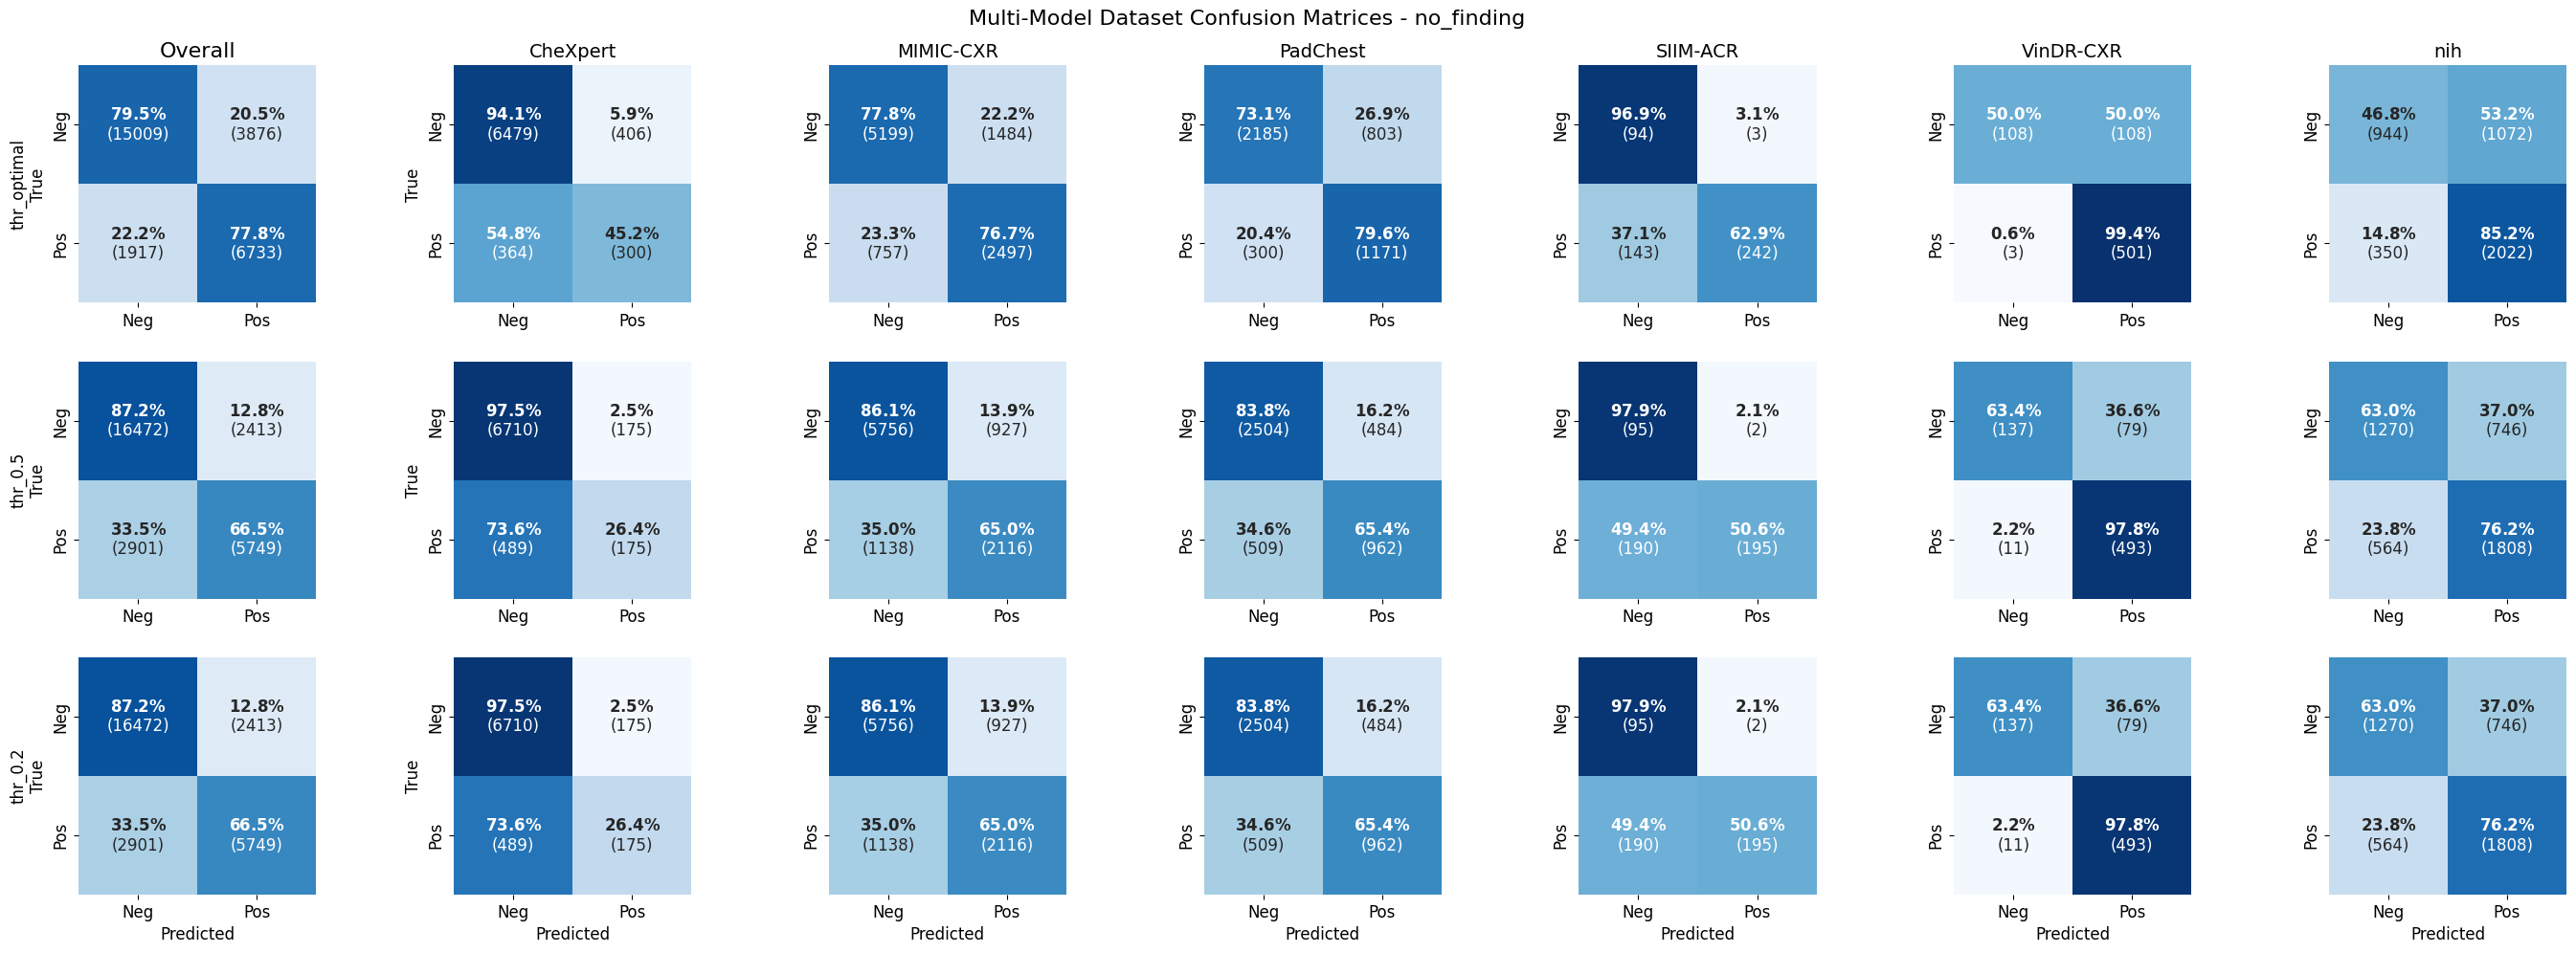


MULTI-MODEL COMPARISON SUMMARY
📊 Aggregated 3 models
📈 Generated ROC and PR comparison plots
📈 Generated ROC and PR plots with individual datasets
📊 Generated comparison plots for 7 metrics
📊 Generated confusion matrix comparison plots
💾 All results saved to: results/validation


In [45]:
# Run comprehensive multi-model evaluation
multi_model_results = evaluate_multiple_models(
    model_evaluation_dict=model_evaluation_dict,
    class_names=class_names,
    save_dir='results/validation',
    log_wandb=False,
    display=True,
    comparison_metrics=None,
)

# Access results
individual_results = multi_model_results['individual_results']
aggregated_results = multi_model_results['aggregated_results']

RESULTS ARE:
- good separation of classes with good auc (0.9) but too many false positives (same as the ratio of the images, 4:1)
- but low F1: using 0.5 threshold we get only 0.48 for pneumothorax
- suggested f1 for maximizing f1 is 0.6 but that gives much more false positives; using 0.8 I get 84% of pneumothorax correct and 84% of non-ptx correct, but given the ratio that is still lots of non-pneumothorax. F1 there is 0.34 (too low), with very low precision (21%)


In [35]:
from cxr.evaluate import evaluate_multiple_models, evaluate_model

In [ ]:
all_valid_results = evaluate_model(y_true, y_probs, class_names, threshold = [0.2, 0.5, 0.5], save_dir = 'results/validation_optimal_th', 
                                   use_optimal_thresholds=True, log_wandb=False, display = True,
                                   n_bootstraps=1000, dataset_values=None)

In [ ]:
all_valid_results = evaluate_model(y_true, y_probs, class_names, threshold = [0.5, 0.5, 0.5], save_dir = 'results/validation_0_5', 
                                   use_optimal_thresholds=False, log_wandb=False, display = True,
                                   n_bootstraps=1000, dataset_values=None)

In [ ]:
all_valid_results = evaluate_model(y_true, y_probs, class_names, threshold = [0.2, 0.5, 0.5], save_dir = 'results/validation_0_2', 
                                   use_optimal_thresholds=False, log_wandb=False, display = True,
                                   n_bootstraps=1000, dataset_values=None)

In [ ]:
# Run comprehensive multi-model evaluation
multi_model_results = evaluate_multiple_models(
    model_evaluation_dict=model_evaluation_dict,
    class_names=class_names,
    save_dir='results/validation',
    log_wandb=False,
    display=True,
    comparison_metrics=None,
)

# Access results
individual_results = multi_model_results['individual_results']
aggregated_results = multi_model_results['aggregated_results']

In [ ]:
# Check

In [28]:
from cxr.evaluate import evaluate_multiple_models, evaluate_model

In [ ]:
weight_path_dictionary_multilabel

In [29]:
df = pd.read_csv('valid_filled.csv')

/tmp/ipykernel_2089403/477880472.py:1: DtypeWarning: Columns (1,2,11,40,43,56,57) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('valid_filled.csv')


In [30]:
model_evaluation_dict = {}
model_path_dictionary = weight_path_dictionary_multilabel

for model_name, model_path in model_path_dictionary.items():
    if model_name == 'all':
        print(model_name)
        print(f'Loading {model_path}')
        # model.load_weights(model_path_dictionary.get(model_name))
        print('Model loaded successfully')
        
        # LOAD THE MODEL
        # y_probs = model.predict(external_test_generator, verbose=1)
        # df = save_predictions_to_df(df, y_probs, class_names, model_name=model_name)
        # df.to_csv('valid_filled.csv', index = False)
        y_true, y_probs = get_predictions_from_df(df, class_names, model_name=model_name, dataset=None)
        dataset_values = df['dataset'].values
    
        # Store evaluation parameters for this model
        model_evaluation_dict[model_name] = {
            'y_true': y_true,
            'y_probs': y_probs,
            'dataset_values': dataset_values,
            'threshold': [0.2, 0.5, 0.5],
            'use_optimal_thresholds': True,
            'n_bootstraps': 1000,
        }




all
Loading wandb/run-20250429_005742-771kvn05/files/best_model_5_2.keras
Model loaded successfully


In [ ]:
# Run comprehensive multi-model evaluation
multi_model_results = evaluate_multiple_models(
    model_evaluation_dict=model_evaluation_dict,
    class_names=class_names,
    save_dir='results/validation_check',
    log_wandb=False,
    display=True,
    comparison_metrics=None,
)

# Access results
individual_results = multi_model_results['individual_results']
aggregated_results = multi_model_results['aggregated_results']